<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/24_Poisoning_Attacks_Against_QML/QNN_PoisoningUnlearning_Gadani2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Self-revealing poisons: detecting and unlearning poisoned training data in a quantum neural network (Gadani et al.) step by step

This notebook re-implements, runs and checks the method of

> Oum Gadani, Kandarp Gajjar, Himani Trivedi and Hiren Patel,
> "Self-revealing poisons: loss-guided forensic detection and quantum unlearning of corrupted training data",
> *Physica Scripta* **101** (2026) 336001. DOI [10.1088/1402-4896/ae9810](https://doi.org/10.1088/1402-4896/ae9810)
> (received 8 May 2026, published 19 August 2026).

The paper publishes no code, so everything below is written from the method as the paper describes it.

**The story in four sentences.** An attacker flips the labels of a fraction $\varepsilon$ of the training set of a small quantum neural network (QNN) with the
*QUID* attack (each poisoned sample gets the label of the class that is farthest away in Hilbert space). A defender who owns a *clean reference model* can then score every
training sample by the **loss difference** between the clean and the poisoned model: the poisoned model has memorised the wrong labels (low loss) while the clean model still finds
them surprising (high loss), so the poisons "reveal themselves". An unsupervised threshold turns the scores into a candidate *forget set*, and five unlearning methods
(gradient ascent, SCRUB, continued fine-tuning, Fisher forgetting, relative gradient ascent) repair the model without retraining it from scratch.

**What the notebook does.**
1. Downloads MNIST, builds the paper's MNIST-4 task (digits 0 to 3, 1000 images, 700 train / 300 test) and compresses each image to 8 numbers with an auto-encoder.
2. Builds the paper's 4-qubit hybrid QNN (angle encoding, PQC-8, amplitude-damping + depolarising noise $p=0.05$, Pauli-Z read-out, linear layer) on an *exact* density-matrix simulator,
   and **proves** that it is the same circuit as the PennyLane `default.mixed` circuit that is drawn.
3. Runs the QUID attack for the paper's poison ratios and three seeds (Table 4 / Fig. 2 to 4).
4. Detects the poisoned samples with the loss-difference signal and the hybrid K-means/GMM threshold (Fig. 5, 6, Tables 5, 6).
5. Unlearns the detected samples with the five methods (Fig. 7, Tables 7, 8), then repeats the whole defence as a label-free defender on three held-out seeds (Table 12, Fig. 10).
6. Repeats the pipeline on classical MLPs (Sec. 4.6, Fig. 8, 9), trains classical baselines (SVC, random forest) on the very same inputs and labels, and re-computes the appendix ablations (Tables 9 to 11).
7. Prints the paper's numbers next to the notebook's and gives a verdict per claim.

**How to run.** Open in Google Colab, choose a CPU runtime and *Runtime > Run all*. With `FAST_MODE = True` (default) the notebook finishes in roughly 10 to 15 minutes on a CPU (one seed, a coarse poison grid, 12 epochs);
with `FAST_MODE = False` it follows the paper's budgets (three seeds, all fifteen poison ratios, 30 epochs, three held-out seeds, six classical seeds) and needs about two hours on a busy shared 8-thread CPU (the executed copy in the repository was produced this way: 120 minutes; an idle machine should need roughly half of that).
MNIST is public and not gated; the Hugging Face token cell is only used by a fallback mirror (if you ever need a token, add it as the Colab secret `HF_TOKEN`; it is never printed).

**What you get at the end.** A table of 80+ numbers from the paper with this notebook's value and a verdict (reproduced / exceeded / not reached / cannot be checked), a critical reading of the paper, and five exercises.


## The paper in one page

**Problem.** Quantum machine-learning models built from parameterised quantum circuits (PQCs) are trained in the cloud, where an attacker can corrupt the training set. Existing quantum *unlearning* methods
(gradient reversal, SCRUB, Fisher dampening ...) assume the defender knows exactly which samples to forget (a "fully known forget set", FKFS). After a poisoning attack the defender knows nothing ("fully unknown forget set", FUFS).

**Threat: QUID** (Kundu and Ghosh, 2025). Indiscriminate label-flipping poisoning: a fraction $\varepsilon$ of the 700 training samples is relabelled with the class whose *encoded quantum states* are farthest in Hilbert space from the sample
(geometry-aware, "maximally inconsistent" labels). Only the training set is changed; the test set stays clean.

**Victim.** MNIST-4 (digits 0 to 3, 250 images each, 700 train / 300 test); a convolutional auto-encoder maps each image to 8 numbers scaled to angles in $[0, 2\pi]$; angle encoding with RX gates into 4 qubits (two layers);
PQC-8 (4 qubits, 2 layers of RY + RZ per qubit with a linear CNOT chain); amplitude-damping + depolarising noise with $p = 0.05$ (PennyLane `default.mixed`); Pauli-Z read-out and a classical linear head;
cross-entropy, 30 epochs, batch 32, learning rate 0.01, SPSA for the quantum parameters and Adam for the classical head; seeds 42, 1, 24.

**Stage 1, detection (SRP).** The defender owns a clean *reference model* $f_{clean}$ (it may be trained on other data of the same task). For every training sample (with its possibly poisoned label) compute
$\text{loss\_diff} = \ell(f_{clean}) - \ell(f_{poisoned})$. Scores above a threshold are flagged:
$$T_{final} = (1-w)\,T_{K\text{-}means} + w\,T_{GMM}, \qquad w = 0.6$$
where $T_{K\text{-}means}$ and $T_{GMM}$ are the decision boundaries of a 2-cluster K-means and a 2-component Gaussian mixture on the scores. The attack is called *self-revealing* because the signal separates better as $\varepsilon$ grows.

**Stage 2, unlearning.** With the flagged set $D_f$ and the rest $D_r$: **GA** (maximise the loss on $D_f$, minimise on $D_r$), **SCRUB** (student diverges from the frozen teacher on $D_f$, stays close on $D_r$), **CF** (continued fine-tuning on $D_r$ only),
**Fisher forgetting** (one-shot selective synaptic dampening, $\lambda = 0.1$) and **RGA** (forget-set gradient divided by the retain-set gradient magnitude). Iterative methods: 20 steps, batch 32, Adam, learning rate 0.005.

**Claims to check.** Clean baseline 83.0 % (seed 42) and a steep accuracy drop between $\varepsilon = 0.3$ and $0.4$; ROC AUC $\ge 0.986$ and PR AUC rising from 0.956 to 0.9995 for $\varepsilon \in [0.1, 0.9]$; mean operating-point F1 about 0.93;
GA, SCRUB and CF recover accuracy to within 10 points of the clean baseline for $\varepsilon \le 0.5$ (e.g. 84.7 % at 0.1, 84.3 % at 0.3, 78.0 % at 0.5, 59.3 % at 0.7), CF at about half the cost; a label-free defender ($w = 0.5$, held-out seeds)
reaches ROC AUC 0.97; the same pipeline works on classical MLPs (ROC AUC $\ge 0.99$). Everything runs on simulators.


### What follows the paper and what had to be chosen

The paper is a 20-page journal article without code. Where it is silent or inconsistent, the choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | MNIST-4, 250 images per digit, 700 / 300 split | the same; public MNIST training file (S3 mirror, Google mirror, Hugging Face fallback); a new class-balanced draw and stratified split for every seed |
| Encoder | convolutional auto-encoder, 784 -> 64 -> 8, 20 epochs, Adam 1e-3, MSE (Table 2) | dense auto-encoder 784-64-8 (mirrored decoder, sigmoid output), same 20 epochs / Adam / MSE, batch 32 (CHOICE), trained on the 700 *unlabelled* training images only |
| Angle range | features scaled to $[0, 2\pi]$ | **chosen on a validation split of the training data** among $[0, 2\pi]$ (paper) and $[0, \pi]$ (Section 3; the choice is printed). The paper-literal value is reported next to it |
| Encoding gates | "RX gates", "Rx or Ry", "two encoding layers" for 8 numbers on 4 qubits | layer 1: RX with features 0 to 3; layer 2: RY with features 4 to 7 (two RX on one qubit would just add the angles) |
| Circuit | "PQC-8 (4 qubits, 2 layers), RY + RZ per qubit, linear CNOT" (Table 3); the text also calls it "circuit 8 of Sim et al." (which has controlled-RX gates) | Table 3 is followed: per layer RY, RZ on every qubit, then CNOT(0,1), CNOT(1,2), CNOT(2,3); 16 trainable angles |
| Noise | amplitude damping + depolarising, $p = 0.05$, `default.mixed` | the same channels after every gate on every wire it touches (order: damping, then depolarising; CHOICE). Exact density-matrix simulation in NumPy, **asserted equal** to PennyLane `default.mixed` |
| Read-out | not stated (shots?) | exact $\langle Z\rangle$ of every qubit (CHOICE), then a linear layer 4 -> 4 |
| Training | 30 epochs, batch 32, lr 0.01, SPSA (quantum) + Adam (classical) | the same; SPSA perturbation 0.1 rad (CHOICE), SPSA gradient fed to Adam; **learning rate chosen on validation data** among 0.01 (paper), 0.05, 0.1 (CHOICE, Section 3); accuracy of the last epoch is reported |
| QUID | label of the class whose quantum prototype is farthest | farthest mean Frobenius distance between the encoded density matrices and all training samples of each class (true labels; the sample itself excluded) |
| Poison subset | random fraction $\varepsilon$ of 700 | `rng(10000 + seed)` permutation, first $\text{round}(\varepsilon\cdot 700)$ samples; same initial weights and batch order for every $\varepsilon$ of a seed |
| Reference model | "any clean model for a similar task" | the same QNN, budget and learning rate trained on 700 correctly labelled images of digits 0 to 3 that are *not* in the victim's data (different seed) |
| Signal | loss difference of clean and poisoned model | $\text{loss\_diff} = CE_{clean} - CE_{poisoned}$ on the training sample with its possibly poisoned label |
| Threshold | K-means and 2-component GMM boundaries, $w = 0.6$ (tuned), $w = 0.5$ (a priori) | K-means: midpoint of the two centroids; GMM: score where the posterior of the upper component is 1/2 (CHOICE); same $w$ values |
| Unlearning budget | 20 steps, batch 32, Adam lr 0.005 | the paper-literal budget is **always evaluated**; the reported budget of every iterative method is picked among three candidates (literal, 20 steps with lr 0.025, 100 steps with lr 0.025) on the defender's clean reference data, never on the test set (Section 6) |
| Circuit gradients in unlearning | not stated | SPSA (as in training); exact gradient for the linear layer; Fisher information from finite differences of the exact simulator |
| Fisher forgetting | $\lambda = 0.1$ | SSD of Foster et al.: dampen parameters with $F_f > \alpha F_r$ by $\min(\lambda F_r / F_f, 1)$; $\alpha = 10$ (CHOICE, the SSD default) |
| RGA | forget gradient times the inverse of the retain-gradient magnitude | $-g_f/(|g_r| + 10^{-6})$ per parameter, then Adam |
| Classical baseline | MLPs 784-16-4-4 and 8-16-4-4 (six seeds); classical analogue of QUID | the same architectures with PyTorch; farthest class by mean Euclidean distance in the input space; Adam lr 0.01, batch 32, same epochs as the QNN (CHOICE); six seeds (42, 1, 24, 101, 202, 303) |
| Seeds | 42, 1, 24 (held out: 101, 202, 303) | the same |
| 5-fold cross-validation (Table 4, right) | reported | **not run** (about 50 extra PQC-8 trainings per seed) |

The consequences of the largest deviations (auto-encoder, angle range, learning rate) are discussed in "Reading the paper critically".


## 0. Setup


In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "torch", "huggingface_hub", "pyarrow") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" huggingface_hub pyarrow
    if importlib.util.find_spec("torch") is None:
        %pip install -q "torch==2.14.1" --index-url https://download.pytorch.org/whl/cpu
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All required packages already present; skipping pip install.")


All required packages already present; skipping pip install.


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE = False           # True : class demo (one seed, a coarse poison grid, 12 training epochs) -- a few minutes on a laptop CPU.
                           # False: the paper's budgets (seeds 42/1/24, 15 poison ratios, 30 epochs, 3 held-out seeds, 6 classical seeds).
                           #        About 1 to 1.5 hours on a shared 8-thread CPU (see the timing printed at the end of every section).
SEED = 42                  # first seed of the paper (it uses 42, 1 and 24)
SEEDS         = [42]            if FAST_MODE else [42, 1, 24]      # paper Sec. 3.2: three random seeds
HELDOUT_SEEDS = [101]           if FAST_MODE else [101, 202, 303]  # paper App. A.3: seeds held out of the weight search
CLASSICAL_SEEDS = [42]          if FAST_MODE else [42, 1, 24, 101, 202, 303]   # paper Sec. 4.6: six seeds for the MLPs

# --- data and encoder (paper Tables 2 and 3) ---
CLASSES    = [0, 1, 2, 3]  # MNIST-4: digits 0 to 3
N_SAMPLES  = 1000          # 250 per class; 700 train / 300 test
TEST_FRAC  = 0.3
N_QUBITS   = 4
N_FEATURES = 8             # latent size of the auto-encoder: two angles per qubit
AE_EPOCHS  = 20            # auto-encoder: 784 -> 64 -> 8, Adam, lr 1e-3, MSE, 20 epochs
ANGLE_MAX  = 6.283185307179586   # features scaled to [0, 2 pi] (paper Sec. 3.1); Section 3 re-selects it on a validation split
CALIB_GRID = [(a, l) for a in (6.283185307179586, 3.141592653589793) for l in ((0.01, 0.05) if FAST_MODE else (0.01, 0.05, 0.1))]   # (angle range, learning rate) candidates

# --- victim QNN training (paper Table 3) ---
EPOCHS   = 12 if FAST_MODE else 30  # paper: 30
LR       = 0.01            # Adam learning rate, paper: 0.01 (Section 3 re-selects it on a validation split of the training data)
BATCH    = 32              # paper: 32
SPSA_C   = 0.1             # CHOICE: SPSA perturbation (radians); the paper does not give it
P_NOISE  = 0.05            # amplitude damping + depolarising after every gate, paper: p = 0.05
N_LAYERS = 2               # PQC-8 of Table 3: 2 layers

# --- poisoning grid (paper Sec. 3.2): eps in {0, 0.01, 0.025, 0.05, 0.075, 0.1, ..., 1.0} ---
EPS_ALL = [0.0, 0.01, 0.025, 0.05, 0.075] + [round(0.1 * k, 1) for k in range(1, 11)]
EPS_SUB = [0.01, 0.025, 0.05, 0.075]                      # sub-threshold regime
EPS_MAIN = [round(0.1 * k, 1) for k in range(1, 10)]      # 0.1 ... 0.9, the detection/unlearning range
if FAST_MODE:
    EPS_ALL = [0.0, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9]
    EPS_SUB = [0.05]
    EPS_MAIN = [0.1, 0.3, 0.5, 0.7, 0.9]
EPS_HELDOUT = [0.1, 0.3, 0.5, 0.7] if FAST_MODE else EPS_MAIN   # paper A.3: ROC/PR on 0.1-0.9, CF unlearning on 0.1-0.7

# --- detection (paper Sec. 3.3) ---
W_TUNED   = 0.6            # mixing weight of the paper (selected on seeds 42, 1, 24)
W_APRIORI = 0.5            # label-free defender of App. A.3

# --- unlearning (paper Sec. 3.4) ---
UNL_STEPS = 20             # iterative methods: 20 steps, batch 32, Adam lr 0.005
UNL_BATCH = 32
UNL_LR    = 0.005
UNL_GRID  = [(20, 0.005), (20, 0.025), (100, 0.025)]   # CHOICE: candidate (steps, Adam lr) budgets; the first is the paper-literal one (Section 8 picks per method on clean reference data)
FISHER_LAMBDA = 0.1        # dampening strength of the one-shot Fisher method
FISHER_ALPHA  = 1.0        # CHOICE: dampen a parameter when its forget-set Fisher exceeds its retain-set Fisher; not given in the paper (the original SSD default 10 selects no parameter at all here)

DATA_DIR  = "data"         # downloaded MNIST files are cached here (relative to the working directory)
IBM_TOKEN = ""             # not used: the paper ran on simulators only
print(f"FAST_MODE={FAST_MODE} | seeds {SEEDS} | held-out seeds {HELDOUT_SEEDS} | epochs {EPOCHS} | eps grid {EPS_ALL}")


FAST_MODE=False | seeds [42, 1, 24] | held-out seeds [101, 202, 303] | epochs 30 | eps grid [0.0, 0.01, 0.025, 0.05, 0.075, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


In [3]:
import os, io, gzip, time, struct, copy, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import sklearn, scipy
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from scipy.optimize import brentq

import torch
import torch.nn as nn
import torch.nn.functional as F
import pennylane as qml

from threadpoolctl import threadpool_limits
threadpool_limits(1)                         # the matrices are tiny (256 x 256): one BLAS thread is much faster than many fighting for the cores
torch.set_num_threads(2)                     # the networks are tiny as well
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)            # every experiment below builds its own generator from SEED-based integers
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 120)

# Hugging Face token (only used by the optional mirror fallback for MNIST; MNIST itself is not gated).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
print("torch", torch.__version__, "| pennylane", qml.__version__)
T_NOTEBOOK_START = time.time()


numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1
torch 2.14.1+cpu | pennylane 0.45.1


## 1. Data and the auto-encoder

MNIST is downloaded from a public mirror (the Hugging Face copy `ylecun/mnist` is the fallback) and cached in `DATA_DIR`. For each seed we draw 250 training-file images of each digit 0 to 3 (1000 images), split them 70 : 30 with stratification,
train the auto-encoder on the 700 training images (no labels), and rescale the 8 latent numbers to angles. The defender additionally gets a separate, correctly labelled **reference set** of 700 images of the same four digits that is disjoint from the victim's 1000 images.
Everything that is fitted (auto-encoder, scaler) sees the training split only; test and reference values are clipped to the training range.


In [4]:
MNIST_SOURCES = ["https://ossci-datasets.s3.amazonaws.com/mnist/{f}", "https://storage.googleapis.com/cvdf-datasets/mnist/{f}"]
MNIST_FILES = ("train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz")

def _read_idx(raw):
    magic, = struct.unpack(">I", raw[:4]); nd = magic & 0xFF
    dims = struct.unpack(">" + "I" * nd, raw[4:4 + 4 * nd])
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * nd).reshape(dims)

def _download(urls, path):
    import requests
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=(10, 120)); r.raise_for_status()
            open(path, "wb").write(r.content); return path
        except Exception as e:
            last = e; print("  download failed:", u, type(e).__name__)
    raise RuntimeError(f"all mirrors failed for {path}: {last}")

def load_mnist(data_dir=DATA_DIR):
    """MNIST training set (60000 images, uint8 28x28) and labels; cached as a compressed npz in DATA_DIR."""
    cache = os.path.join(data_dir, "mnist_train.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["x"], z["y"]
    try:
        pi = _download([u.format(f=MNIST_FILES[0]) for u in MNIST_SOURCES], os.path.join(data_dir, MNIST_FILES[0]))
        pl = _download([u.format(f=MNIST_FILES[1]) for u in MNIST_SOURCES], os.path.join(data_dir, MNIST_FILES[1]))
        x = _read_idx(gzip.open(pi).read()); y = _read_idx(gzip.open(pl).read())
    except Exception:                                         # fallback: Hugging Face parquet mirror of MNIST (not gated)
        print("  S3/GCS mirrors unreachable; using the Hugging Face mirror ylecun/mnist")
        from huggingface_hub import hf_hub_download
        from PIL import Image
        df = pd.read_parquet(hf_hub_download("ylecun/mnist", "mnist/train-00000-of-00001.parquet", repo_type="dataset", token=HF_TOKEN or None))
        x = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]); y = df["label"].values
    x = np.ascontiguousarray(x); y = np.asarray(y).astype(int)
    np.savez_compressed(cache, x=x, y=y)
    return x, y

t0 = time.time()
MNIST_X, MNIST_Y = load_mnist()
print(f"MNIST training set: {MNIST_X.shape[0]} images of {MNIST_X.shape[1]}x{MNIST_X.shape[2]}, loaded in {time.time() - t0:.0f} s")

class Autoencoder(nn.Module):
    """784 -> 64 -> 8 encoder (paper Table 2: 'Encoder architecture 784 -> 64 -> 8 (auto-encoder)') and a mirror-image decoder.
    # CHOICE: dense layers with ReLU (the text calls it a 'convolutional' auto-encoder, Table 2 lists a 784-64-8 stack); sigmoid output."""
    def __init__(self, d=N_FEATURES):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(784, 64), nn.ReLU(), nn.Linear(64, d))
        self.dec = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 784), nn.Sigmoid())
    def forward(self, x):
        return self.dec(self.enc(x))

def train_autoencoder(x_train, seed, epochs=AE_EPOCHS, lr=1e-3, batch=32):
    """20 epochs, Adam lr 1e-3, MSE (paper Table 2). Trained on the (unlabelled) training images only."""
    g = torch.Generator().manual_seed(seed); torch.manual_seed(seed)
    ae = Autoencoder(); opt = torch.optim.Adam(ae.parameters(), lr=lr); X = torch.tensor(x_train, dtype=torch.float32)
    for ep in range(epochs):
        perm = torch.randperm(len(X), generator=g)
        for s in range(0, len(X), batch):
            xb = X[perm[s:s + batch]]; opt.zero_grad(); F.mse_loss(ae(xb), xb).backward(); opt.step()
    with torch.no_grad(): final = F.mse_loss(ae(X), X).item()
    return ae, final

_BASE_CACHE = {}
def _base_data(seed):
    """MNIST-4 for one seed: 250 images of each digit 0-3 (1000), stratified 700/300 split, auto-encoder -> 8 numbers -> [0, 2 pi].
    Also draws a disjoint, correctly labelled *reference* set of 700 images of the same four digits for the defender's clean model.
    The auto-encoder and the angle scaler are fitted on the 700 training images only; test / reference values are clipped to the training range."""
    if seed in _BASE_CACHE: return _BASE_CACHE[seed]
    r = np.random.default_rng(seed); per = N_SAMPLES // len(CLASSES); sel, ref = [], []
    for c in CLASSES:
        ids = r.permutation(np.where(MNIST_Y == c)[0]); sel.append(ids[:per]); ref.append(ids[per:2 * per])
    sel, ref = np.concatenate(sel), np.concatenate(ref)
    ysel, yref_all = MNIST_Y[sel], MNIST_Y[ref]
    itr, ite = train_test_split(np.arange(len(sel)), test_size=TEST_FRAC, stratify=ysel, random_state=seed)
    iref, _ = train_test_split(np.arange(len(ref)), train_size=700, stratify=yref_all, random_state=seed)
    img = lambda ids: MNIST_X[ids]
    xtr, xte, xref = img(sel[itr]), img(sel[ite]), img(ref[iref])
    flat = lambda a: a.reshape(len(a), -1).astype(np.float32) / 255.0
    ae, ae_mse = train_autoencoder(flat(xtr), seed)
    def lat(a):
        with torch.no_grad(): return ae.enc(torch.tensor(flat(a))).numpy().astype(float)
    ltr, lte, lref = lat(xtr), lat(xte), lat(xref)
    d = dict(seed=seed, img_tr=xtr, img_te=xte, img_ref=xref, ytr=ysel[itr], yte=ysel[ite], yref=yref_all[iref],
             lat_tr=ltr, lat_te=lte, lat_ref=lref, ae_mse=ae_mse, ae=ae, classes=list(range(len(CLASSES))))
    _BASE_CACHE[seed] = d
    return d

def scale_angles(lat_fit, others, amax):
    """Min-max scale the latent numbers to [0, amax]; the scaler is fitted on `lat_fit` (training latents only), the others are clipped."""
    mm = MinMaxScaler((0.0, amax)).fit(lat_fit)
    return mm.transform(lat_fit), [np.clip(mm.transform(o), 0, amax) for o in others]

def get_data(seed):
    """Base data of `_base_data` plus the angles ftr / fte / fref scaled to [0, ANGLE_MAX] (current value of the global ANGLE_MAX)."""
    d = dict(_base_data(seed))
    d["ftr"], (d["fte"], d["fref"]) = scale_angles(d["lat_tr"], [d["lat_te"], d["lat_ref"]], ANGLE_MAX)
    return d

dat = get_data(SEED)
print(f"seed {SEED}: train {dat['ftr'].shape}, test {dat['fte'].shape}, reference {dat['fref'].shape} | train class counts {np.bincount(dat['ytr'])} | "
      f"auto-encoder reconstruction MSE {dat['ae_mse']:.4f} | angle range {dat['ftr'].min():.2f} to {dat['ftr'].max():.2f}")


MNIST training set: 60000 images of 28x28, loaded in 1 s


seed 42: train (700, 8), test (300, 8), reference (700, 8) | train class counts [175 175 175 175] | auto-encoder reconstruction MSE 0.0337 | angle range 0.00 to 6.28


## 2. The hybrid quantum neural network and an exact simulator

**Model.** Each image becomes 8 angles. Layer 1 rotates qubit $q$ by RX($a_q$), layer 2 by RY($a_{q+4}$). The trainable PQC-8 has two layers, each with RY($\theta$) and RZ($\theta$) on every qubit and a CNOT chain 0-1, 1-2, 2-3
(16 angles). After every gate the paper's noise is applied (amplitude damping with $p = 0.05$, then depolarising with $p = 0.05$) on each wire the gate touches. The model outputs $\langle Z\rangle$ of the four qubits, and a linear layer (4 -> 4) gives the class logits.

**Simulator.** A 4-qubit density matrix has 256 entries, and the noise makes it mixed, so we simulate it exactly. We write each qubit's $2\times 2$ density matrix in the Pauli basis (four real numbers), so the whole state is a real vector of length 256 and every gate or
noise channel is a real matrix. This is exact (no sampling) and fast enough to train 80 networks. The circuit section further below **asserts** that this simulator and PennyLane's `default.mixed` give the same density matrix to 1e-10.

**Training.** Adam on all parameters, batch 32, cross-entropy. For the circuit, the gradient is an **SPSA** estimate: all 16 angles are shifted at once by $\pm c\,\Delta$ with random signs, the loss is evaluated twice, and
$g_i \approx \frac{L(\theta + c\Delta) - L(\theta - c\Delta)}{2c}\Delta_i$. The linear layer uses its exact gradient.


In [5]:
# ---------------------------------------------------------------- single-qubit gates and noise as 4x4 superoperators
# A 2x2 density matrix is stored row-major as a length-4 vector; vec(K rho K^dag) = kron(K, conj(K)) vec(rho).
def rx_mat(a):
    a = np.asarray(a, dtype=float); c, s = np.cos(a / 2), np.sin(a / 2)
    U = np.zeros(a.shape + (2, 2), dtype=complex)
    U[..., 0, 0] = c; U[..., 1, 1] = c; U[..., 0, 1] = -1j * s; U[..., 1, 0] = -1j * s
    return U

def ry_mat(a):
    a = np.asarray(a, dtype=float); c, s = np.cos(a / 2), np.sin(a / 2)
    U = np.zeros(a.shape + (2, 2), dtype=complex)
    U[..., 0, 0] = c; U[..., 1, 1] = c; U[..., 0, 1] = -s; U[..., 1, 0] = s
    return U

def rz_mat(a):
    a = np.asarray(a, dtype=float)
    U = np.zeros(a.shape + (2, 2), dtype=complex)
    U[..., 0, 0] = np.exp(-0.5j * a); U[..., 1, 1] = np.exp(0.5j * a)
    return U

ROT = {"rx": rx_mat, "ry": ry_mat, "rz": rz_mat}

def superop_unitary(U):
    """(...,2,2) unitary -> (...,4,4) superoperator."""
    return np.einsum("...ia,...jc->...ijac", U, U.conj()).reshape(U.shape[:-2] + (4, 4))

def noise_superop(gamma=0.0, lam=0.0):
    """Amplitude damping(gamma) followed by depolarising (rho -> (1-lam) rho + lam I/2), as one 4x4 superoperator."""
    K0 = np.array([[1, 0], [0, np.sqrt(1 - gamma)]], dtype=complex)
    K1 = np.array([[0, np.sqrt(gamma)], [0, 0]], dtype=complex)
    S_ad = np.kron(K0, K0.conj()) + np.kron(K1, K1.conj())
    vI = np.array([1, 0, 0, 1], dtype=complex)
    S_dep = (1 - lam) * np.eye(4, dtype=complex) + lam * 0.5 * np.outer(vI, vI)
    return S_dep @ S_ad

class PaperNoise:
    """The paper's simulated noise: AmplitudeDamping(p) then DepolarizingChannel(p) after EVERY gate, on every wire the gate touches.
    # CHOICE: the order amplitude damping -> depolarising is not stated."""
    def __init__(self, p):
        self.p = p; self.name = f"p={p}"
        self.S = None if p == 0 else noise_superop(gamma=p, lam=4 * p / 3)       # PennyLane DepolarizingChannel(p) <=> lam = 4p/3

# ---------------------------------------------------------------- encoding circuit: product states
ENC_SEQ = ("rx", "ry")        # CHOICE: angle encoding with RX on features 0-3 then RY on features 4-7 (paper: 'RX gates', 'two encoding layers', 'Rx or Ry')

def encode_product(X, n, noise, seq=ENC_SEQ):
    """Noisy angle-encoding circuit: rotation seq[k] with angle X[:, k*n + q] on qubit q, noise after every rotation.
    Returns the per-qubit density matrices (N, n, 4); the full state is their tensor product."""
    N = X.shape[0]
    vec = np.zeros((N, n, 4), dtype=complex); vec[..., 0] = 1.0
    for k, g in enumerate(seq):
        U = ROT[g](X[:, k * n:(k + 1) * n])
        vec = np.einsum("...ab,...b->...a", superop_unitary(U), vec)
        if noise.S is not None: vec = vec @ noise.S.T
    return vec

# ---------------------------------------------------------------- the 4-qubit density matrix as a real "Pauli vector"
# Every qubit's 2x2 density matrix is described by the four real numbers c_k = Tr(rho sigma_k), sigma = (I, X, Y, Z).  The 4-qubit state is a real
# vector of length 4^4 = 256 (digit q = Pauli index of qubit q).  A single-qubit gate or noise channel is a real 4x4 matrix acting on one digit,
# a CNOT is a real 256 x 256 matrix, and <Z_q> is simply the entry "Z on qubit q, identity elsewhere".  Real arithmetic makes the simulation 4x
# cheaper than complex density matrices.  The PennyLane check below compares the full 16x16 density matrix, so nothing here is taken on trust.
T1 = np.array([[1, 0, 0, 1], [0, 1, 1, 0], [0, 1j, -1j, 0], [1, 0, 0, -1]], dtype=complex)      # vec(rho) -> (c_I, c_X, c_Y, c_Z)
T1_INV = np.linalg.inv(T1)

def to_pauli_rep(S):
    """4x4 superoperator in the vec(rho) basis -> real 4x4 matrix in the Pauli basis."""
    P = T1 @ S @ T1_INV
    assert np.abs(P.imag).max() < 1e-10
    return P.real

def product_to_pauli(vec):
    """(N,n,4) per-qubit vec(rho) -> (N, 4^n) real Pauli vectors (outer product over qubits; qubit 0 = most significant digit)."""
    c = (vec @ T1.T).real
    N, n, _ = c.shape
    out = c[:, 0]
    for q in range(1, n):
        out = (out[:, :, None] * c[:, q][:, None, :]).reshape(N, -1)
    return out

def _embed(mats, n):
    """Dense 4^n x 4^n matrix = Kronecker product of the n 4x4 matrices in `mats` (list)."""
    M = mats[0]
    for S in mats[1:]:                                                    # Kronecker product by broadcasting (faster than np.kron here)
        a, b = M.shape[0], S.shape[0]
        M = (M[:, None, :, None] * S[None, :, None, :]).reshape(a * b, a * b)
    return M

def pauli_to_rho(v, n):
    """(N, 4^n) real Pauli vectors -> (N, 2^n, 2^n) density matrices (used for checks only)."""
    N = v.shape[0]
    w = v @ _embed([T1_INV] * n, n).T                                     # back to vec(rho) digits (p = 2 r + c)
    x = w.reshape((N,) + (2, 2) * n)                                      # axes: r0 c0 r1 c1 ...
    rows = [1 + 2 * q for q in range(n)]; cols = [2 + 2 * q for q in range(n)]
    return x.transpose([0] + rows + cols).reshape(N, 2 ** n, 2 ** n)

def cnot_pair_perm(c, t, n):
    """Index permutation of CNOT(control c, target t) on vec(rho) digits: the target's row bit and column bit are flipped by the control's row / column bit."""
    perm = np.empty(4 ** n, dtype=int)
    for i in range(4 ** n):
        d = [(i >> (2 * (n - 1 - q))) & 3 for q in range(n)]                 # pair digits p = 2 r + c
        r, cc = [x >> 1 for x in d], [x & 1 for x in d]
        r[t] ^= r[c]; cc[t] ^= cc[c]
        perm[i] = sum(((2 * r[q] + cc[q]) << (2 * (n - 1 - q))) for q in range(n))
    return perm

def pqc8_ops(n=N_QUBITS, layers=N_LAYERS):
    """Gate list of PQC-8 as in the paper's Table 3: per layer RY and RZ on every qubit, then a linear chain of CNOTs.
    Each op is (gate, wires, parameter index or None).  # CHOICE: Table 3 ('RY + RZ per qubit, linear CNOT entanglement, 2 layers') is followed;
    the text calls the circuit 'circuit 8 of Sim et al.' (which uses controlled-RX gates) -- the two descriptions disagree."""
    ops, k = [], 0
    for _ in range(layers):
        for q in range(n):
            ops.append(("ry", (q,), k)); k += 1
            ops.append(("rz", (q,), k)); k += 1
        for q in range(n - 1):
            ops.append(("cnot", (q, q + 1), None))
    return ops, k

_COMPILED = {}
def compile_pqc(ops, noise, n):
    """Group the gate list into blocks: runs of single-qubit gates (kept symbolic: they depend on theta) and runs of CNOTs (fixed real matrices:
    the CNOT permutation followed by the noise channel on both wires).  Every gate is followed by the noise channel on each wire it touches."""
    key = (n, noise.p, tuple((g, w) for g, w, _ in ops))
    if key in _COMPILED: return _COMPILED[key]
    Tn, Tn_inv = _embed([T1] * n, n), _embed([T1_INV] * n, n)
    noise_p = to_pauli_rep(noise.S) if noise.S is not None else np.eye(4)
    blocks, i = [], 0
    while i < len(ops):
        if ops[i][0] == "cnot":
            M = np.eye(4 ** n, dtype=complex)
            while i < len(ops) and ops[i][0] == "cnot":
                _, w, _ = ops[i]; perm = cnot_pair_perm(w[0], w[1], n)
                P = np.zeros((4 ** n, 4 ** n), dtype=complex); P[perm, np.arange(4 ** n)] = 1.0          # new[perm[i]] = old[i]
                E = _embed([noise.S if (q in w and noise.S is not None) else np.eye(4, dtype=complex) for q in range(n)], n)
                M = E @ P @ M; i += 1
            Mp = Tn @ M @ Tn_inv; assert np.abs(Mp.imag).max() < 1e-9
            blocks.append(("fixed", np.ascontiguousarray(Mp.real.T)))       # stored transposed: new_v = v @ M.T
        else:
            seq = []
            while i < len(ops) and ops[i][0] != "cnot":
                seq.append((ops[i][0], ops[i][1][0], ops[i][2])); i += 1
            blocks.append(("rot", seq))
    _COMPILED[key] = (blocks, noise_p)
    return _COMPILED[key]

def run_pqc(v, ops, theta, noise, n):
    """Run the (noisy) PQC on real Pauli vectors.  Equivalent to applying the gates one by one (checked against PennyLane below), but the
    single-qubit gates of a layer are multiplied into one Kronecker product and the CNOT chain (with its noise) is one precomputed matrix."""
    blocks, noise_p = compile_pqc(ops, noise, n)
    for kind, payload in blocks:
        if kind == "fixed":
            v = v @ payload
        else:
            S = {}
            for g, q, k in payload:
                Sg = to_pauli_rep(superop_unitary(ROT[g](theta[k])))
                if noise.S is not None: Sg = noise_p @ Sg
                S[q] = Sg @ S[q] if q in S else Sg
            v = v @ _embed([S.get(q, np.eye(4)) for q in range(n)], n).T
    return v

Z_IDX = {n: np.array([3 * 4 ** (n - 1 - q) for q in range(n)]) for n in (N_QUBITS,)}      # "Z on qubit q, identity elsewhere"
def z_from_pauli(v, n):
    return v[:, Z_IDX[n]]

OPS, N_THETA = pqc8_ops()
print(f"PQC-8: {len(OPS)} gates, {N_THETA} trainable circuit parameters, {sum(g == 'cnot' for g, _, _ in OPS)} CNOTs")


PQC-8: 22 gates, 16 trainable circuit parameters, 6 CNOTs


In [6]:
NOISE = PaperNoise(P_NOISE)
EVAL_COUNTER = [0]            # number of (sample, circuit) evaluations performed so far -- the cost measure of the unlearning methods

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def ce_per_sample(logits, y):
    p = softmax(logits); return -np.log(p[np.arange(len(y)), y] + 1e-12)

def ce_loss(logits, y):
    return ce_per_sample(logits, y).mean()

class Adam:
    def __init__(self, shape, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.m = np.zeros(shape); self.v = np.zeros(shape); self.t = 0; self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
    def step(self, g):
        self.t += 1; self.m = self.b1 * self.m + (1 - self.b1) * g; self.v = self.b2 * self.v + (1 - self.b2) * g * g
        return self.lr * (self.m / (1 - self.b1 ** self.t)) / (np.sqrt(self.v / (1 - self.b2 ** self.t)) + self.eps)

class Enc:
    """Noisy encoded states of a set of samples: per-qubit vectors always, the full 16 x 16 density matrices (as real Pauli vectors) on demand."""
    def __init__(self, X, n=N_QUBITS, noise=NOISE):
        self.n, self.noise, self.X = n, noise, X
        self.vec = encode_product(X, n, noise); self._pauli = None
    def pauli(self):
        if self._pauli is None: self._pauli = product_to_pauli(self.vec)
        return self._pauli
    def take(self, idx):
        e = object.__new__(Enc); e.n, e.noise, e.X = self.n, self.noise, self.X[idx]
        e.vec = self.vec[idx]; e._pauli = None if self._pauli is None else self._pauli[idx]
        return e

class QNN:
    """Hybrid QNN of the paper: noisy angle encoding (fixed) -> PQC-8 (trainable, 16 angles) -> <Z> of every qubit -> linear layer (4 -> 4)."""
    def __init__(self, n=N_QUBITS, n_classes=4, noise=NOISE, rng=None):
        self.n, self.C, self.noise = n, n_classes, noise
        self.ops, self.n_params = pqc8_ops(n)
        rng = rng or np.random.default_rng(0)
        self.theta = rng.uniform(0, 2 * np.pi, self.n_params)                     # CHOICE: random weights in [0, 2 pi)
        bound = 1 / np.sqrt(n)                                                      # same as torch.nn.Linear's default initialisation
        self.W = rng.uniform(-bound, bound, (n, n_classes)); self.b = rng.uniform(-bound, bound, n_classes)
    def features(self, enc, theta=None):
        theta = self.theta if theta is None else theta
        EVAL_COUNTER[0] += len(enc.X)
        return z_from_pauli(run_pqc(enc.pauli(), self.ops, theta, self.noise, self.n), self.n)
    def logits(self, enc, theta=None, W=None, b=None):
        W = self.W if W is None else W; b = self.b if b is None else b
        return self.features(enc, theta) @ W + b
    def predict(self, enc):
        return self.logits(enc).argmax(1)
    def copy(self):
        m = object.__new__(QNN); m.__dict__.update({k: (v.copy() if isinstance(v, np.ndarray) else v) for k, v in self.__dict__.items()}); return m

def train_qnn(model, enc_tr, y_tr, enc_te, y_te, epochs, lr, batch, seed, spsa_c=SPSA_C, lr_theta=None):
    """Paper Table 3: Adam, lr 0.01, batch 32, cross-entropy, 'SPSA (quantum) + Adam (classical)': the circuit gradient is a SPSA estimate (two
    circuit evaluations per step, Rademacher perturbation of size spsa_c) fed to Adam; the linear layer uses its exact gradient.
    Test accuracy and loss are recorded after every epoch (monitoring only; nothing is selected on them)."""
    r = np.random.default_rng(seed)
    N = len(y_tr); opt_t = Adam(model.theta.shape, lr if lr_theta is None else lr_theta); opt_w = Adam(model.W.shape, lr); opt_b = Adam(model.b.shape, lr)
    hist = {"epoch": [], "test_acc": [], "test_loss": [], "train_loss": []}
    def log(ep):
        lg = model.logits(enc_te); hist["epoch"].append(ep); hist["test_acc"].append(float((lg.argmax(1) == y_te).mean()))
        hist["test_loss"].append(float(ce_loss(lg, y_te)))
    log(0)
    for ep in range(1, epochs + 1):
        perm = r.permutation(N); tl = []
        for s in range(0, N, batch):
            idx = perm[s:s + batch]; e = enc_tr.take(idx); y = y_tr[idx]
            delta = r.choice([-1.0, 1.0], model.theta.shape)
            lp = ce_loss(model.logits(e, model.theta + spsa_c * delta), y); lm = ce_loss(model.logits(e, model.theta - spsa_c * delta), y)
            g_theta = (lp - lm) / (2 * spsa_c) * delta                               # SPSA (for Rademacher perturbations 1/delta = delta)
            z = model.features(e); p = softmax(z @ model.W + model.b); tl.append(ce_loss(z @ model.W + model.b, y))
            p[np.arange(len(y)), y] -= 1; p /= len(y)
            model.W -= opt_w.step(z.T @ p); model.b -= opt_b.step(p.sum(0)); model.theta -= opt_t.step(g_theta)
        hist["train_loss"].append(float(np.mean(tl))); log(ep)
    return hist

def confusion(y, p, C=4):
    M = np.zeros((C, C), dtype=int)
    for a, b in zip(y, p): M[a, b] += 1
    return M


### 2.1 The same circuit as a PennyLane QNode

The function below writes the circuit with PennyLane gates, taking the gate list `OPS` of the simulator; the circuit section further below draws it and proves the equivalence.


In [7]:
# The executed circuit written as a PennyLane QNode: encoding (RX layer, RY layer), PQC-8 (2 x [RY, RZ on every qubit + CNOT chain]),
# and -- in the noisy version -- AmplitudeDamping(p) then DepolarizingChannel(p) after every gate on every wire it touches.
def make_qnode(p, return_state=False):
    dev = qml.device("default.mixed", wires=N_QUBITS)
    def noisy(ws):
        if p > 0:
            for w in ws:
                qml.AmplitudeDamping(p, wires=w); qml.DepolarizingChannel(p, wires=w)
    @qml.qnode(dev)
    def circuit(x, theta):
        for k, g in enumerate(ENC_SEQ):                              # encoding: layer k rotates qubit q by feature k*4+q
            for q in range(N_QUBITS):
                (qml.RX if g == "rx" else qml.RY)(x[k * N_QUBITS + q], wires=q); noisy([q])
        qml.Barrier(wires=range(N_QUBITS))
        for g, w, k in OPS:                                          # trainable PQC-8, taken from the very gate list the simulator runs
            if g == "cnot": qml.CNOT(wires=list(w))
            else: (qml.RY if g == "ry" else qml.RZ)(theta[k], wires=w[0])
            noisy(w)
        qml.Barrier(wires=range(N_QUBITS))
        if return_state: return qml.density_matrix(list(range(N_QUBITS)))
        return [qml.expval(qml.PauliZ(q)) for q in range(N_QUBITS)]
    return circuit

def simulator_state(x, theta, p):
    """The NumPy simulator's full density matrix for one sample (for the equivalence check)."""
    noise = PaperNoise(p); vec = encode_product(x[None], N_QUBITS, noise)
    return pauli_to_rho(run_pqc(product_to_pauli(vec), OPS, theta, noise, N_QUBITS), N_QUBITS)[0]


## 3. Choosing the angle range and the learning rate on validation data

The paper-literal setting (angles in $[0, 2\pi]$, learning rate 0.01) is unreliable in this simulator: an angle of 0 and an angle of $2\pi$ are the same quantum state, so the extremes of the latent range are confused, and with noise after every gate the circuit outputs are small, so the
linear layer needs a larger step size. Rather than guessing, we train clean models on 70 % of the 700 training samples and score them on the other 30 % for every candidate (the **test set is not used**); the best candidate is used everywhere below,
the paper-literal one is printed for reference. The first grid entry is always the paper's own setting.


In [8]:
def validation_accuracy(amax, lr, seed=SEED, epochs=EPOCHS):
    """Train a clean PQC-8 QNN on 70 % of the 700 training samples (scaler fitted on that part only) and score it on the other 30 %.
    The test set is never touched."""
    d = _base_data(seed); y = d["ytr"]
    ia, iv = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=seed)
    fa, (fv,) = scale_angles(d["lat_tr"][ia], [d["lat_tr"][iv]], amax)
    ea, ev = Enc(fa), Enc(fv)
    m = QNN(rng=np.random.default_rng(seed))
    h = train_qnn(m, ea, y[ia], ev, y[iv], epochs, lr, BATCH, seed)
    return float(np.mean(h["test_acc"][-3:]))              # mean of the last three epochs: less sensitive to one lucky epoch

ANGLE_NAME = {True: "2 pi", False: "pi"}
t0 = time.time(); rows = []
for amax, lr in CALIB_GRID:
    rows.append(dict(angle_range="[0, 2 pi]" if amax > 4 else "[0, pi]", lr=lr, val_acc=100 * validation_accuracy(amax, lr)))
    print(f"  {rows[-1]['angle_range']:10s} lr={lr:<5} validation accuracy {rows[-1]['val_acc']:.1f} %   [{time.time() - t0:.0f} s]", flush=True)
calib = pd.DataFrame(rows)
paper_row = calib.iloc[0]                                  # first grid entry = the paper's literal setting (2 pi, 0.01)
best = int(calib.val_acc.values.argmax())
ANGLE_MAX, LR = CALIB_GRID[best]                           # CHOICE: setting with the best validation accuracy (ties: first = closest to the paper)
print(f"\npaper-literal setting ([0, 2 pi], lr 0.01): {paper_row.val_acc:.1f} %  |  selected: angle range [0, {ANGLE_NAME[ANGLE_MAX > 4]}], lr {LR}  ({calib.val_acc.max():.1f} %)")


  [0, 2 pi]  lr=0.01  validation accuracy 51.1 %   [11 s]


  [0, 2 pi]  lr=0.05  validation accuracy 57.3 %   [23 s]


  [0, 2 pi]  lr=0.1   validation accuracy 51.7 %   [34 s]


  [0, pi]    lr=0.01  validation accuracy 67.8 %   [44 s]


  [0, pi]    lr=0.05  validation accuracy 74.4 %   [54 s]


  [0, pi]    lr=0.1   validation accuracy 68.3 %   [64 s]



paper-literal setting ([0, 2 pi], lr 0.01): 51.1 %  |  selected: angle range [0, pi], lr 0.05  (74.4 %)


## Dataset Exploration and Visualisation

All plots show **real MNIST images** or their real compressed coordinates, coloured by the ground-truth digit; nothing here is simulated or invented. The cells print the dataset shape, the 8 feature names, the original label values and the
class counts, plot the class distribution, and then show where the observations lie: (a) the raw pixels projected on their first two principal components, (b) the 8 auto-encoder numbers projected on their first two principal components, and (c) the first two
angles that the quantum circuit actually receives (scaled to the selected angle range). PCA is fitted on the training split only.


In [9]:
d = get_data(SEED)
ANGLE_LABEL = "[0, 2 pi]" if ANGLE_MAX > 4 else "[0, pi]"
FEATURE_NAMES = [f"angle_{k} ({'RX' if k < N_QUBITS else 'RY'} on qubit {k % N_QUBITS})" for k in range(N_FEATURES)]
print("Dataset: MNIST-4 = the handwritten digits 0, 1, 2, 3 of MNIST (real images; nothing is simulated or invented)")
print(f"full MNIST training file : {MNIST_X.shape} images (uint8), original label values {np.unique(MNIST_Y).tolist()}")
print(f"images   : train {d['img_tr'].shape}, test {d['img_te'].shape}, defender's reference set {d['img_ref'].shape}")
print(f"features : {len(FEATURE_NAMES)} numbers per image from the auto-encoder (784 -> 64 -> 8), min-max scaled to angles in {ANGLE_LABEL}:")
for k, nme in enumerate(FEATURE_NAMES): print(f"   feature {k}: {nme}")
tab = pd.DataFrame({"digit": CLASSES,
                    "MNIST train file": [int((MNIST_Y == c).sum()) for c in CLASSES],
                    "train (700)": np.bincount(d["ytr"], minlength=4), "test (300)": np.bincount(d["yte"], minlength=4),
                    "reference (700)": np.bincount(d["yref"], minlength=4)}).set_index("digit")
print("\nOriginal label values and class counts (digit = class):"); print(tab.to_string())
print("\nTraining angles (seed", SEED, "), summary:"); print(pd.DataFrame(d["ftr"], columns=[f"angle_{k}" for k in range(N_FEATURES)]).describe().loc[["mean", "std", "min", "max"]].round(2).to_string())


Dataset: MNIST-4 = the handwritten digits 0, 1, 2, 3 of MNIST (real images; nothing is simulated or invented)
full MNIST training file : (60000, 28, 28) images (uint8), original label values [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
images   : train (700, 28, 28), test (300, 28, 28), defender's reference set (700, 28, 28)
features : 8 numbers per image from the auto-encoder (784 -> 64 -> 8), min-max scaled to angles in [0, pi]:
   feature 0: angle_0 (RX on qubit 0)
   feature 1: angle_1 (RX on qubit 1)
   feature 2: angle_2 (RX on qubit 2)
   feature 3: angle_3 (RX on qubit 3)
   feature 4: angle_4 (RY on qubit 0)
   feature 5: angle_5 (RY on qubit 1)
   feature 6: angle_6 (RY on qubit 2)
   feature 7: angle_7 (RY on qubit 3)

Original label values and class counts (digit = class):
       MNIST train file  train (700)  test (300)  reference (700)
digit                                                            
0                  5923          175          75              175
1                  6

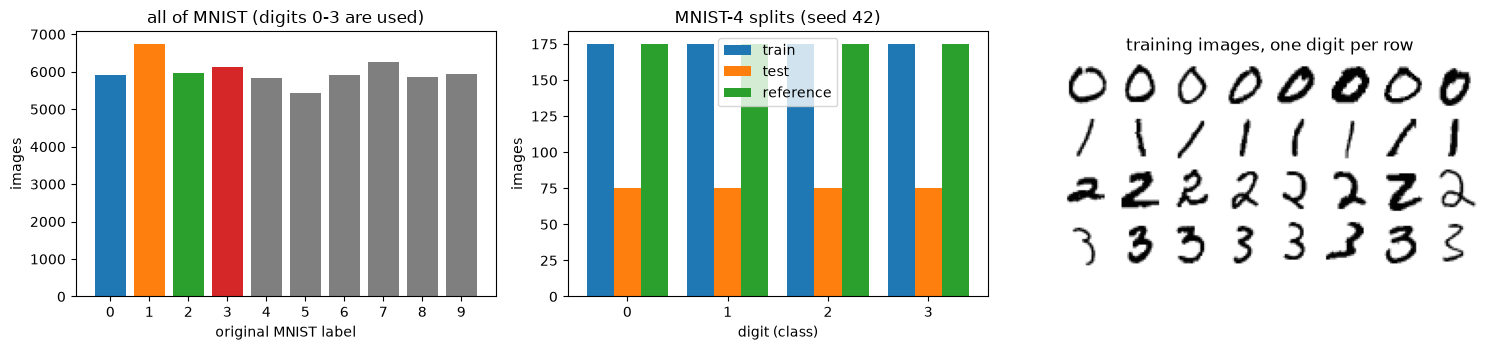

In [10]:
DIGIT_COLORS = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
cnt = np.bincount(MNIST_Y, minlength=10)
ax[0].bar(range(10), cnt, color=["tab:gray" if c not in CLASSES else DIGIT_COLORS[CLASSES.index(c)] for c in range(10)])
ax[0].set_xticks(range(10)); ax[0].set_xlabel("original MNIST label"); ax[0].set_ylabel("images"); ax[0].set_title("all of MNIST (digits 0-3 are used)")
w = 0.27
for k, (name, y) in enumerate([("train", d["ytr"]), ("test", d["yte"]), ("reference", d["yref"])]):
    ax[1].bar(np.arange(4) + (k - 1) * w, np.bincount(y, minlength=4), w, label=name)
ax[1].set_xticks(range(4)); ax[1].set_xlabel("digit (class)"); ax[1].set_ylabel("images"); ax[1].set_title("MNIST-4 splits (seed %d)" % SEED); ax[1].legend()
ax[2].axis("off")
rows = 4; cols = 8
big = np.ones((rows * 28, cols * 28))
for c in range(4):
    ids = np.where(d["ytr"] == c)[0][:cols]
    for j, i in enumerate(ids): big[c * 28:(c + 1) * 28, j * 28:(j + 1) * 28] = 1 - d["img_tr"][i] / 255.0
ax[2].imshow(big, cmap="gray", vmin=0, vmax=1); ax[2].set_title("training images, one digit per row")
plt.tight_layout(); plt.show()


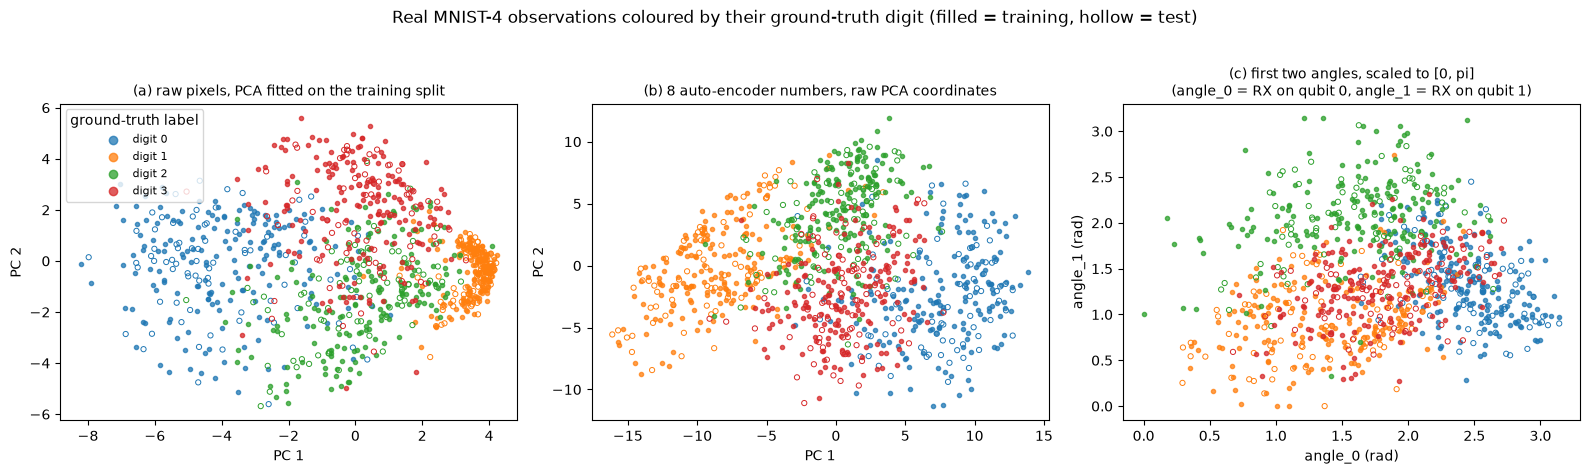

explained variance of the 2 PCA axes: pixels 24.8 %, auto-encoder numbers 61.4 %


In [11]:
def digit_scatter(ax, P, y, title, xl, yl, P_test=None, y_test=None):
    for c in range(4):
        m = y == c; ax.scatter(P[m, 0], P[m, 1], s=9, color=DIGIT_COLORS[c], alpha=0.75, label=f"digit {c}")
        if P_test is not None:
            mt = y_test == c; ax.scatter(P_test[mt, 0], P_test[mt, 1], s=14, facecolors="none", edgecolors=DIGIT_COLORS[c], linewidths=0.7)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)

flat = lambda a: a.reshape(len(a), -1).astype(float) / 255.0
pca_pix = PCA(2, random_state=SEED).fit(flat(d["img_tr"]))                       # fitted on the training split only
pca_lat = PCA(2, random_state=SEED).fit(d["lat_tr"])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
digit_scatter(ax[0], pca_pix.transform(flat(d["img_tr"])), d["ytr"], "(a) raw pixels, PCA fitted on the training split", "PC 1", "PC 2",
              pca_pix.transform(flat(d["img_te"])), d["yte"])
digit_scatter(ax[1], pca_lat.transform(d["lat_tr"]), d["ytr"], "(b) 8 auto-encoder numbers, raw PCA coordinates", "PC 1", "PC 2",
              pca_lat.transform(d["lat_te"]), d["yte"])
digit_scatter(ax[2], d["ftr"][:, :2], d["ytr"], f"(c) first two angles, scaled to {ANGLE_LABEL}\n(angle_0 = RX on qubit 0, angle_1 = RX on qubit 1)", "angle_0 (rad)", "angle_1 (rad)",
              d["fte"][:, :2], d["yte"])
ax[0].legend(markerscale=2, fontsize=8, title="ground-truth label")
fig.suptitle("Real MNIST-4 observations coloured by their ground-truth digit (filled = training, hollow = test)", y=1.02)
plt.tight_layout(); plt.show()
print("explained variance of the 2 PCA axes: pixels %.1f %%, auto-encoder numbers %.1f %%" %
      (100 * pca_pix.explained_variance_ratio_.sum(), 100 * pca_lat.explained_variance_ratio_.sum()))


## Quantum Circuit Architecture

The circuit below is the PennyLane QNode of exactly the gate list (`OPS`) that the NumPy simulator executes in every experiment: angle encoding (RX layer, RY layer), the trainable PQC-8 (2 layers of RY, RZ on every qubit plus a CNOT chain)
and the $\langle Z\rangle$ read-out; the second drawing adds the paper's noise channels after every gate. Assumptions where the paper is silent: the encoding gates (RX then RY), the order of the two noise channels, exact expectation values instead of shots,
random initial angles in $[0, 2\pi)$, and the circuit layout itself (Table 3 says "RY + RZ per qubit, linear CNOT", the text says "circuit 8 of Sim et al."; Table 3 is followed). Only one architecture is trained and evaluated (the same circuit is used for the attacked victims, the clean reference models and the unlearned models).


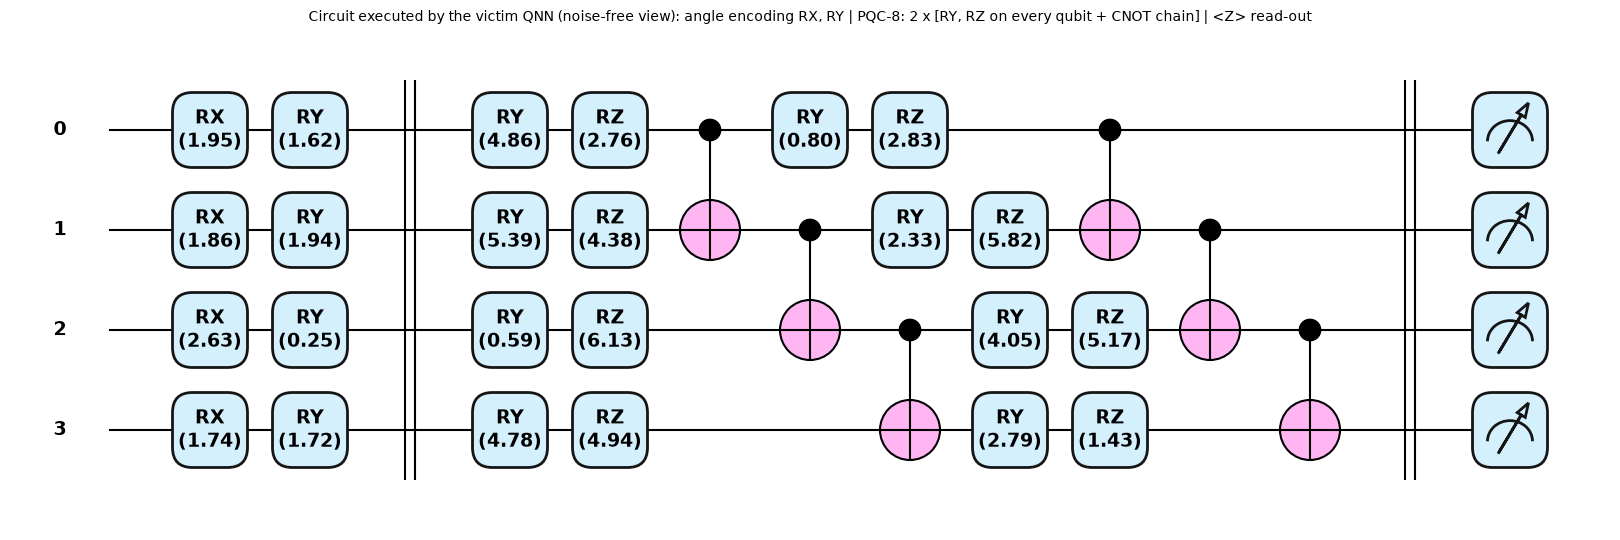

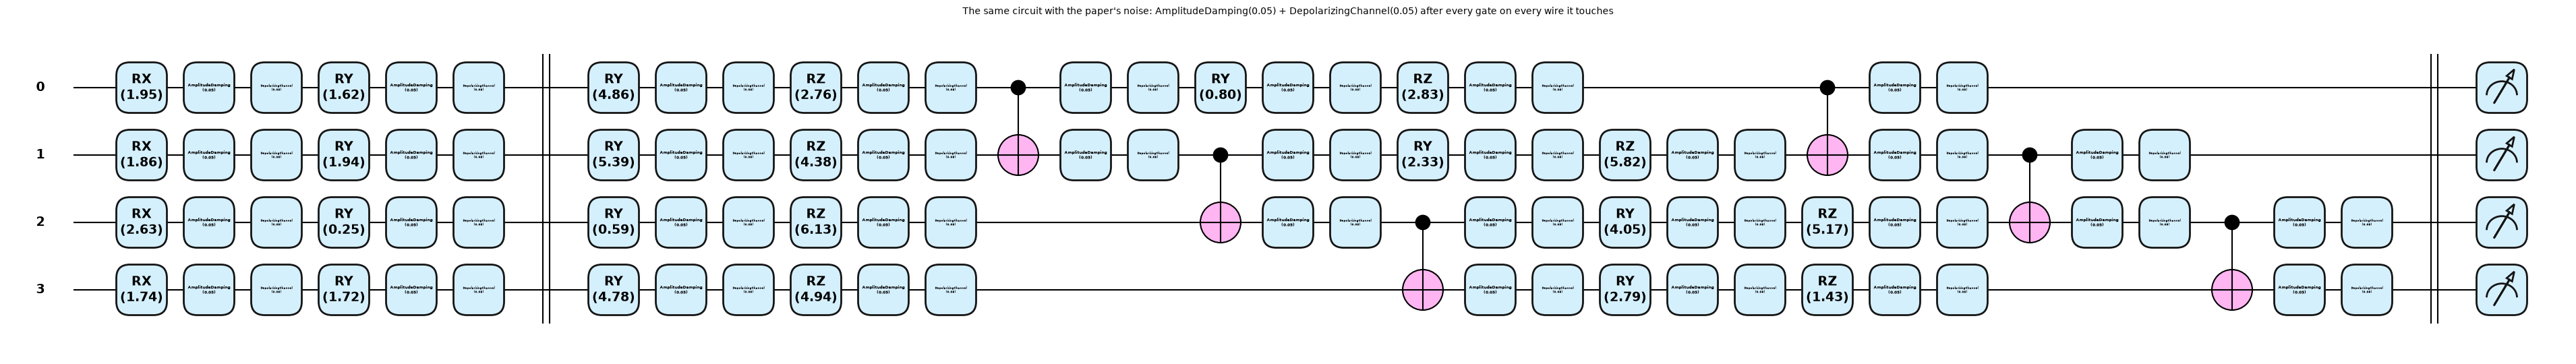

qubits                         : 4
circuit depth (noise-free)     : 13   (gate counts: {'RX': 4, 'RY': 12, 'Barrier': 2, 'RZ': 8, 'CNOT': 6})
gates (encoding 8 + PQC-8 22) : 30;  noise channels in the noisy version: 72
trainable parameters           : 16 circuit angles (RY/RZ, 2 layers x 4 qubits x 2) + 20 in the classical linear layer (4 -> 4 with bias)
measurement                    : <Z> on every qubit (exact expectation values, no shot noise: CHOICE, the paper does not state shots)


In [12]:
x0 = d["ftr"][0]; th0 = np.random.default_rng(SEED).uniform(0, 2 * np.pi, N_THETA)        # one real training sample and random circuit angles
ideal, noisy = make_qnode(0.0), make_qnode(P_NOISE)

fig, ax = qml.draw_mpl(ideal, decimals=2, style="pennylane")(x0, th0)
fig.suptitle("Circuit executed by the victim QNN (noise-free view): angle encoding RX, RY | PQC-8: 2 x [RY, RZ on every qubit + CNOT chain] | <Z> read-out", y=1.04, fontsize=10)
plt.show()

fig, ax = qml.draw_mpl(noisy, decimals=2, style="pennylane")(x0, th0)
fig.suptitle(f"The same circuit with the paper's noise: AmplitudeDamping({P_NOISE}) + DepolarizingChannel({P_NOISE}) after every gate on every wire it touches", y=1.04, fontsize=10)
plt.show()

sp = qml.specs(ideal)(x0, th0)
res = sp["resources"] if isinstance(sp, dict) else sp.resources
ops_nb = len(OPS) + 2 * N_QUBITS
print(f"qubits                         : {N_QUBITS}")
print(f"circuit depth (noise-free)     : {res.depth}   (gate counts: {dict(res.gate_types)})")
print(f"gates (encoding {2 * N_QUBITS} + PQC-8 {len(OPS)}) : {ops_nb};  noise channels in the noisy version: {2 * (2 * N_QUBITS + sum(len(w) for _, w, _ in OPS))}")
print(f"trainable parameters           : {N_THETA} circuit angles (RY/RZ, 2 layers x 4 qubits x 2) + {QNN().W.size + QNN().b.size} in the classical linear layer (4 -> 4 with bias)")
print("measurement                    : <Z> on every qubit (exact expectation values, no shot noise: CHOICE, the paper does not state shots)")


In [13]:
# The training/attack/defence code runs on the NumPy Pauli-vector simulator; the circuit drawn above is the PennyLane QNode of the same gate list.
# This cell proves they are the same circuit: full 16 x 16 density matrices and <Z> values agree to machine precision, with and without noise.
r = np.random.default_rng(1); rows = []
for p in (0.0, P_NOISE):
    qs, qz = make_qnode(p, True), make_qnode(p)
    noise_p = PaperNoise(p); enc = Enc(d["ftr"][:6], noise=noise_p)
    for i in range(6):
        th = r.uniform(0, 2 * np.pi, N_THETA)
        rho_pl = np.array(qs(d["ftr"][i], th)); rho_np = simulator_state(d["ftr"][i], th, p)
        z_pl = np.array(qz(d["ftr"][i], th)); m_tmp = QNN(noise=noise_p); z_np = m_tmp.features(enc.take([i]), th)[0]
        rows.append(dict(noise_p=p, sample=i, max_diff_density_matrix=np.abs(rho_pl - rho_np).max(), max_diff_Z=np.abs(z_pl - z_np).max()))
eq = pd.DataFrame(rows)
print(eq.groupby("noise_p")[["max_diff_density_matrix", "max_diff_Z"]].max().to_string(float_format=lambda v: f"{v:.2e}"))
assert eq.max_diff_density_matrix.max() < 1e-10 and eq.max_diff_Z.max() < 1e-10, "simulator disagrees with PennyLane"
print("\nOK: the NumPy simulator used for every experiment is the circuit drawn above (PennyLane default.mixed), to", f"{max(eq.max_diff_density_matrix.max(), eq.max_diff_Z.max()):.1e}")


         max_diff_density_matrix  max_diff_Z
noise_p                                     
0.00                    1.76e-16    3.89e-16
0.05                    2.32e-13    5.02e-13

OK: the NumPy simulator used for every experiment is the circuit drawn above (PennyLane default.mixed), to 5.0e-13


## 4. The attack: QUID relabelling and its effect on accuracy (paper Sec. 3.2, 4.1, 4.2)

**QUID.** For each of the $\varepsilon\cdot 700$ chosen training samples the new label is the class whose encoded states are **farthest** (largest mean Frobenius distance $\|\rho_a - \rho_b\|_F$ between the noisy encoded density matrices). Because the encoded states are
products of single-qubit states, the distance needs only single-qubit overlaps. The cell trains one victim per (seed, $\varepsilon$) with identical initial weights and batch order, plus one clean reference model per seed, and records the accuracy on the clean test set.


In [14]:
def frobenius_distances(vecA, vecB):
    """Frobenius distances ||rho_a - rho_b||_F between all pairs of (product-state) encoded density matrices; vecA (m,n,4), vecB (k,n,4)
    hold vec(rho) of every qubit.  Tr(A^dag B) of a product state is the product of the single-qubit overlaps."""
    inner = np.einsum("mqa,kqa->mkq", vecA.conj(), vecB).prod(axis=2).real
    nA = (np.abs(vecA) ** 2).sum(axis=2).prod(axis=1); nB = (np.abs(vecB) ** 2).sum(axis=2).prod(axis=1)
    return np.sqrt(np.maximum(nA[:, None] + nB[None, :] - 2 * inner, 0))

def quid_labels(enc_tr, y_true, idx, classes):
    """QUID (Kundu and Ghosh, Algorithm 1; paper Sec. 3.2): the new label of a chosen sample is the class whose encoded quantum states are
    FARTHEST from it in Hilbert space (largest mean Frobenius distance).  The attacker knows the training data and the encoding circuit.
    # CHOICE: the class 'prototype' is the set of all training samples with their true labels (the sample itself is left out of its own class)."""
    D = frobenius_distances(enc_tr.vec[idx], enc_tr.vec)                   # (m, N)
    D[np.arange(len(idx)), idx] = np.nan
    cm = np.stack([np.nanmean(D[:, y_true == c], axis=1) for c in classes], axis=1)
    return np.array(classes)[cm.argmax(1)]

def poison_labels(enc_tr, y_true, eps, seed, classes=(0, 1, 2, 3)):
    """Relabel a fraction eps of the training set with QUID.  Returns (poisoned labels, boolean ground-truth mask of the poisoned samples)."""
    N = len(y_true); npois = int(round(eps * N))
    idx = np.random.default_rng(10_000 + seed).permutation(N)[:npois]
    y = y_true.copy(); mask = np.zeros(N, dtype=bool)
    if npois:
        y[idx] = quid_labels(enc_tr, y_true, idx, list(classes)); mask[idx] = True
    return y, mask

RUNS = {}          # (seed, eps) -> everything about one poisoned victim
REFS = {}          # seed -> clean reference model

_ENC_SETS = {}
def encoded_sets(seed):
    key = (seed, ANGLE_MAX)
    if key not in _ENC_SETS:
        d = get_data(seed); _ENC_SETS[key] = (d, Enc(d["ftr"]), Enc(d["fte"]), Enc(d["fref"]))
    return _ENC_SETS[key]

def get_reference(seed):
    """The defender's clean reference model f_clean: same architecture and budget, trained on 700 correctly labelled images of the same four digits
    that are NOT in the victim's data (the paper: 'need not be trained on the same dataset').  # CHOICE: disjoint reference set."""
    if seed not in REFS:
        d, e_tr, e_te, e_ref = encoded_sets(seed)
        m = QNN(rng=np.random.default_rng(seed + 500)); t = time.time()
        h = train_qnn(m, e_ref, d["yref"], e_te, d["yte"], EPOCHS, LR, BATCH, seed + 500)
        REFS[seed] = dict(model=m, test_acc=h["test_acc"][-1], seconds=time.time() - t)
    return REFS[seed]

def get_run(seed, eps):
    """Train the victim QNN on the QUID-poisoned training set (same initial weights and batch order for every eps of a seed)."""
    key = (seed, round(eps, 4))
    if key not in RUNS:
        d, e_tr, e_te, _ = encoded_sets(seed)
        y_p, mask = poison_labels(e_tr, d["ytr"], eps, seed)
        m = QNN(rng=np.random.default_rng(seed)); t = time.time()
        h = train_qnn(m, e_tr, y_p, e_te, d["yte"], EPOCHS, LR, BATCH, seed)
        pred = m.predict(e_te)
        RUNS[key] = dict(seed=seed, eps=eps, model=m, y_pois=y_p, mask=mask, hist=h, acc=float((pred == d["yte"]).mean()),
                         pred=pred, seconds=time.time() - t, label_correct=float((y_p[mask] == d["ytr"][mask]).mean()) if mask.any() else np.nan)
    return RUNS[key]


### 4.1 The paper's published numbers

Tables 4 to 12 of the paper that this notebook can test, typed in once so that every comparison below uses the same values.


In [15]:
# ---- the numbers published in the paper (Physica Scripta 101, 336001) that this notebook can test ----
PAPER_T4_SEEDS = {   # Table 4 (left): test accuracy of the poisoned QNN, eps -> (seed 42, seed 1, seed 24)
    0.0: (0.8300, 0.7930, 0.8100), 0.1: (0.8067, 0.7670, 0.8330), 0.2: (0.7367, 0.7330, 0.7900), 0.3: (0.7667, 0.5900, 0.7200), 0.4: (0.4100, 0.5470, 0.7130),
    0.5: (0.3933, 0.3300, 0.3930), 0.6: (0.2500, 0.2430, 0.2630), 0.7: (0.0533, 0.0570, 0.0630), 0.8: (0.0133, 0.0430, 0.0000), 0.9: (0.0033, 0.0300, 0.0000)}
PAPER_T4_MEAN = {eps: 100 * float(np.mean(v)) for eps, v in PAPER_T4_SEEDS.items()}
PAPER_T4_STD  = {eps: 100 * float(np.std(v)) for eps, v in PAPER_T4_SEEDS.items()}
PAPER_T5 = {   # Table 5 (seed 42, sub-threshold): eps -> (N poisoned, kmeans_gmm F1, GMM 2-comp F1, Cohen d, accuracy drop %)
    0.010: (7, 0.200, 0.000, 2.38, 0.0), 0.025: (17, 0.588, 0.632, 3.50, 1.7), 0.050: (35, 0.714, 0.722, 3.88, 1.7), 0.075: (52, 0.767, 0.750, 3.85, 0.7)}
PAPER_T6 = {   # Table 6 (seeds 42, 1, 24): eps -> (ROC AUC mean, std, PR AUC mean, std)
    0.1: (0.9899, 0.0023, 0.9556, 0.0196), 0.2: (0.9944, 0.0030, 0.9824, 0.0092), 0.3: (0.9866, 0.0134, 0.9819, 0.0134), 0.4: (0.9938, 0.0036, 0.9913, 0.0051),
    0.5: (0.9955, 0.0018, 0.9954, 0.0021), 0.6: (0.9963, 0.0020, 0.9975, 0.0014), 0.7: (0.9943, 0.0043, 0.9976, 0.0018), 0.8: (0.9964, 0.0043, 0.9990, 0.0012),
    0.9: (0.9963, 0.0026, 0.9995, 0.0004)}
PAPER_T7 = {"GA": (3059.3, "2TB"), "SCRUB": (3175.7, "4TB"), "CF": (1578.4, "TB"), "Fisher": (1715.6, "n"), "RGA": (3076.2, "2TB")}   # Table 7
PAPER_T8 = {   # Table 8: eps -> (this paper's poisoned test accuracy %, Kundu and Ghosh %, best post-unlearning accuracy %, method)
    0.0: (83.0, 81.3, None, None), 0.1: (80.7, 77.3, 84.7, "GA"), 0.3: (76.7, 69.3, 84.3, "SCRUB"), 0.5: (39.3, 20.9, 78.0, "CF"), 0.7: (5.3, 5.6, 59.3, "GA")}
PAPER_T9 = {1.0: 0.9604, 0.75: 0.9605, 0.5: 0.9573, 0.25: 0.9516, 0.0: 0.9445}          # Table 9: Oracle top-eps*N, average F1 vs loss_diff weight
PAPER_T11 = {0.0: 0.8661, 0.1: 0.8798, 0.2: 0.8911, 0.3: 0.9034, 0.4: 0.9141, 0.5: 0.9251, 0.6: 0.9325, 0.7: 0.9316, 0.8: 0.8988, 0.9: 0.8428, 1.0: 0.8331}   # Table 11, kmeans_gmm
PAPER_T12 = {  # Table 12 (held-out seeds 101, 202, 303, w = 0.5): eps -> (ROC AUC mean, std, PR AUC mean, std)
    0.1: (0.934, 0.029, 0.858, 0.049), 0.2: (0.957, 0.005, 0.927, 0.030), 0.3: (0.962, 0.012, 0.950, 0.010), 0.4: (0.975, 0.004, 0.972, 0.001), 0.5: (0.974, 0.006, 0.979, 0.005),
    0.6: (0.980, 0.003, 0.988, 0.002), 0.7: (0.988, 0.002, 0.995, 0.000), 0.8: (0.985, 0.007, 0.996, 0.002), 0.9: (0.994, 0.004, 0.999, 0.000)}
CLEAN_BASELINE_PAPER = 83.0       # seed 42; mean over the three seeds 81.1


### 4.2 Train the clean reference models and the poisoned victims

One reference model per seed and one victim per (seed, poison ratio). The printout shows that QUID labels are (almost) never equal to the true label.


In [16]:
t0 = time.time()
for seed in SEEDS:
    ref = get_reference(seed)
    print(f"seed {seed:3d}: reference model f_clean test accuracy {100 * ref['test_acc']:.1f} %  [{time.time() - t0:.0f} s]", flush=True)
    for eps in EPS_ALL:
        r = get_run(seed, eps)
        extra = f", QUID label equals the true label for {100 * r['label_correct']:.1f} % of the poisoned samples" if eps > 0 else ""
        print(f"seed {seed:3d} eps {eps:5.3f}: test accuracy {100 * r['acc']:5.1f} %{extra}  [{time.time() - t0:.0f} s]", flush=True)
TIME_ATTACK = time.time() - t0
print(f"\nattack grid finished in {TIME_ATTACK / 60:.1f} min")


seed  42: reference model f_clean test accuracy 65.7 %  [14 s]


seed  42 eps 0.000: test accuracy  69.3 %  [37 s]


seed  42 eps 0.010: test accuracy  69.3 %, QUID label equals the true label for 0.0 % of the poisoned samples  [65 s]


seed  42 eps 0.025: test accuracy  69.7 %, QUID label equals the true label for 0.0 % of the poisoned samples  [95 s]


seed  42 eps 0.050: test accuracy  65.3 %, QUID label equals the true label for 2.9 % of the poisoned samples  [125 s]


...

seed  24 eps 0.700: test accuracy   8.7 %, QUID label equals the true label for 2.7 % of the poisoned samples  [1461 s]


seed  24 eps 0.800: test accuracy   7.7 %, QUID label equals the true label for 2.5 % of the poisoned samples  [1491 s]


seed  24 eps 0.900: test accuracy   4.7 %, QUID label equals the true label for 2.2 % of the poisoned samples  [1522 s]


seed  24 eps 1.000: test accuracy   3.7 %, QUID label equals the true label for 2.3 % of the poisoned samples  [1545 s]



attack grid finished in 25.8 min


### 4.3 Accuracy against the poison ratio (paper Table 4, Fig. 2 to 4)

The paper reports a graceful decline up to $\varepsilon\approx 0.3$, a steep drop around $\varepsilon=0.4$, and a collapse below the 25 % random-guess floor at large $\varepsilon$ because the model learns the systematic *wrong* class mapping. The figures show the accuracy per seed with the paper's mean, the confusion matrices, and what QUID does to the labels: each true class is sent consistently to one other class, which looks like a second, coherent concept to the learner.


Test accuracy (%) of the QNN trained on QUID-poisoned data (clean test set), PQC-8, noise p = 0.05  [paper: Table 4, left]
       seed 42  seed 1  seed 24  mean  std  paper mean  paper std
eps                                                              
0.000     69.3    64.0     69.0  67.4  2.4        81.1        1.5
0.010     69.3    65.3     67.0  67.2  1.6         NaN        NaN
0.025     69.7    65.3     65.7  66.9  2.0         NaN        NaN
0.050     65.3    70.7     68.3  68.1  2.2         NaN        NaN
0.075     66.0    70.7     67.0  67.9  2.0         NaN        NaN
0.100     71.3    66.0     63.7  67.0  3.2        80.2        2.7
0.200     68.0    70.0     61.7  66.6  3.6        75.3        2.6
0.300     59.7    55.7     46.0  53.8  5.7        69.2        7.5
0.400     52.3    44.0     33.0  43.1  7.9        55.7       12.4
0.500     37.7    18.7     26.3  27.6  7.8        37.2        3.0
0.600     26.0    10.3     22.7  19.7  6.7        25.2        0.8
0.700     17.3     

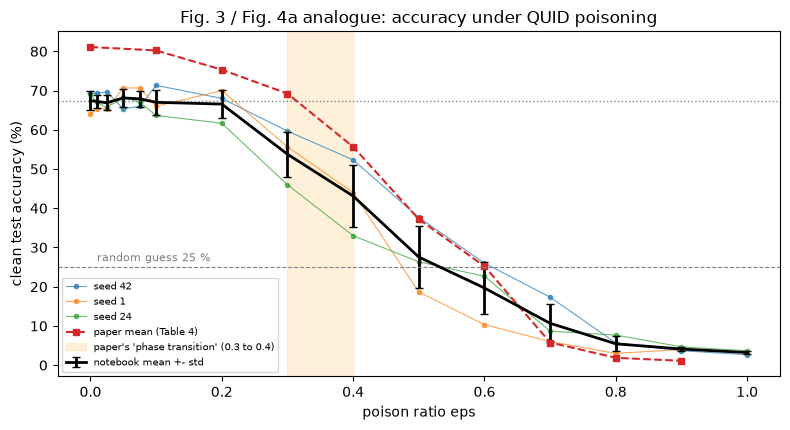

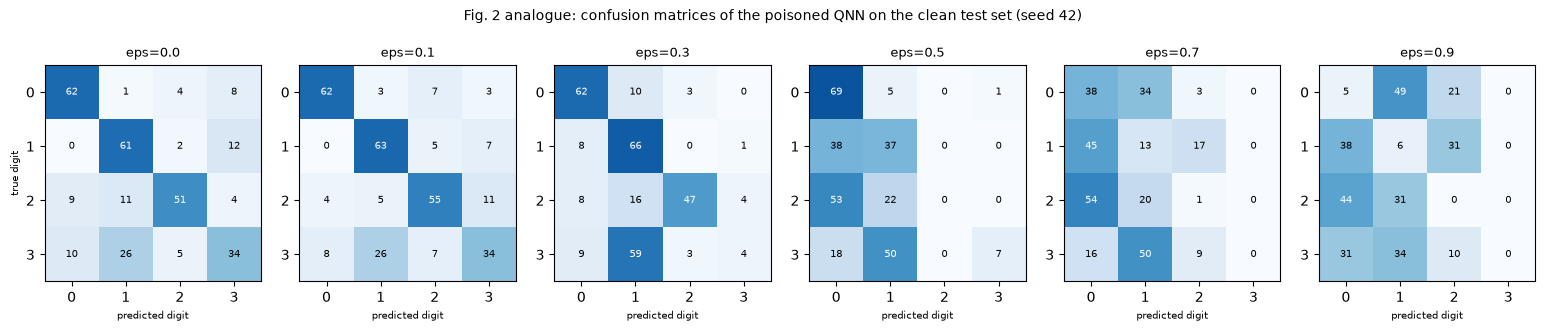

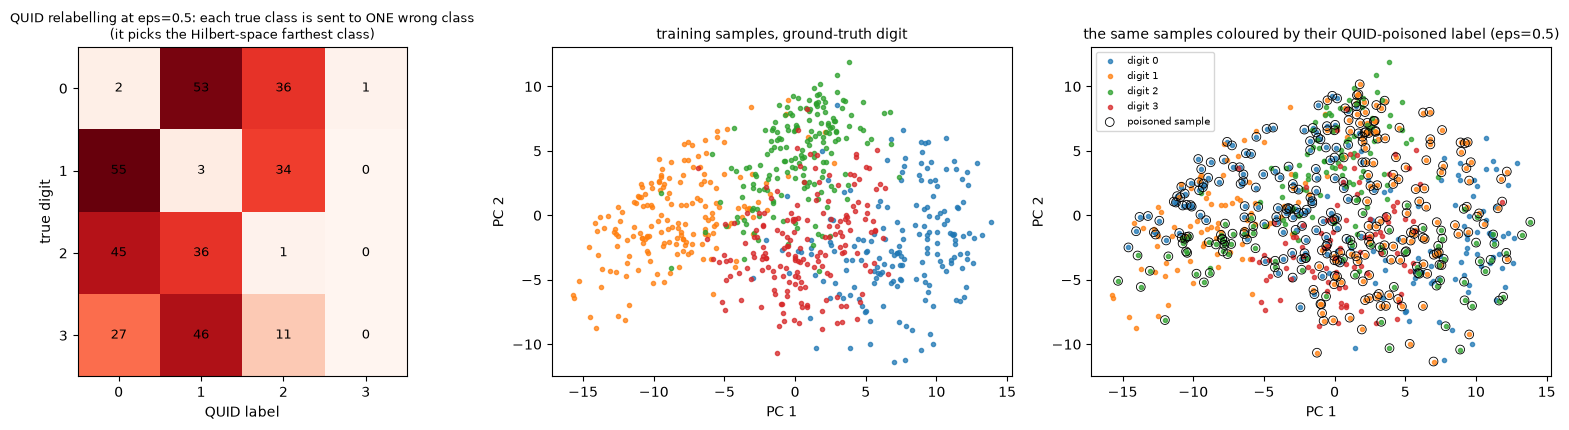

QUID labels equal to the true label: 1.3 % on average (the attack is structurally never right)


In [17]:
acc = pd.DataFrame({f"seed {s}": {e: 100 * get_run(s, e)["acc"] for e in EPS_ALL} for s in SEEDS})
acc["mean"] = acc.mean(axis=1); acc["std"] = acc[[f"seed {s}" for s in SEEDS]].std(axis=1, ddof=0)
acc["paper mean"] = [PAPER_T4_MEAN.get(e, np.nan) for e in acc.index]; acc["paper std"] = [PAPER_T4_STD.get(e, np.nan) for e in acc.index]
acc.index.name = "eps"
print("Test accuracy (%) of the QNN trained on QUID-poisoned data (clean test set), PQC-8, noise p = 0.05  [paper: Table 4, left]")
print(acc.round(1).to_string())
CLEAN_ACC = acc.loc[0.0, "mean"]

fig, ax = plt.subplots(1, 1, figsize=(8, 4.4))
for s in SEEDS: ax.plot(acc.index, acc[f"seed {s}"], "o-", ms=3, lw=0.8, alpha=0.7, label=f"seed {s}")
ax.errorbar(acc.index, acc["mean"], acc["std"], color="k", lw=2, capsize=3, label="notebook mean +- std")
pm_ = acc["paper mean"].dropna(); ax.plot(pm_.index, pm_.values, "s--", color="tab:red", ms=4, label="paper mean (Table 4)")
ax.axhline(CLEAN_ACC, color="gray", ls=":", lw=1); ax.axhline(25, color="gray", ls="--", lw=0.8); ax.text(0.01, 26.5, "random guess 25 %", fontsize=8, color="gray")
ax.axvspan(0.3, 0.4, color="orange", alpha=0.15, label="paper's 'phase transition' (0.3 to 0.4)")
ax.set_xlabel("poison ratio eps"); ax.set_ylabel("clean test accuracy (%)"); ax.set_title("Fig. 3 / Fig. 4a analogue: accuracy under QUID poisoning"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

sel = [e for e in (0.0, 0.1, 0.3, 0.5, 0.7, 0.9) if e in EPS_ALL]
fig, ax = plt.subplots(1, len(sel), figsize=(2.6 * len(sel), 2.9))
for a_, e in zip(np.atleast_1d(ax), sel):
    M = confusion(d["yte"], get_run(SEED, e)["pred"]); a_.imshow(M, cmap="Blues", vmin=0, vmax=80)
    for i in range(4):
        for j in range(4): a_.text(j, i, M[i, j], ha="center", va="center", fontsize=7, color="white" if M[i, j] > 40 else "black")
    a_.set_title(f"eps={e}", fontsize=9); a_.set_xticks(range(4)); a_.set_yticks(range(4)); a_.set_xlabel("predicted digit", fontsize=7)
np.atleast_1d(ax)[0].set_ylabel("true digit", fontsize=7)
fig.suptitle(f"Fig. 2 analogue: confusion matrices of the poisoned QNN on the clean test set (seed {SEED})", y=1.04, fontsize=10)
plt.tight_layout(); plt.show()
# ---- what QUID does to the labels: true class -> QUID class at eps = 0.5 (seed 42), and the geometry of the flip in the PCA plane ----
e_show = 0.5 if 0.5 in EPS_ALL else EPS_ALL[-1]; r = get_run(SEED, e_show); m = r["mask"]
flipmat = np.zeros((4, 4), dtype=int)
for t_, q_ in zip(d["ytr"][m], r["y_pois"][m]): flipmat[t_, q_] += 1
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].imshow(flipmat, cmap="Reds")
for i in range(4):
    for j in range(4): ax[0].text(j, i, flipmat[i, j], ha="center", va="center", fontsize=9)
ax[0].set_xlabel("QUID label"); ax[0].set_ylabel("true digit"); ax[0].set_xticks(range(4)); ax[0].set_yticks(range(4))
ax[0].set_title(f"QUID relabelling at eps={e_show}: each true class is sent to ONE wrong class\n(it picks the Hilbert-space farthest class)", fontsize=9)
P = pca_lat.transform(d["lat_tr"])
digit_scatter(ax[1], P, d["ytr"], "training samples, ground-truth digit", "PC 1", "PC 2")
Pq = P.copy(); digit_scatter(ax[2], Pq, r["y_pois"], f"the same samples coloured by their QUID-poisoned label (eps={e_show})", "PC 1", "PC 2")
ax[2].scatter(P[m, 0], P[m, 1], s=40, facecolors="none", edgecolors="k", linewidths=0.6, label="poisoned sample"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"QUID labels equal to the true label: {100 * np.nanmean([get_run(s, e)['label_correct'] for s in SEEDS for e in EPS_ALL if e > 0]):.1f} % on average (the attack is structurally never right)")


## 5. Stage 1: detecting the poisoned samples (paper Sec. 3.3, 4.3, appendix)

**Signal.** $\text{loss\_diff}_i = CE(f_{clean}(x_i), \tilde y_i) - CE(f_{poisoned}(x_i), \tilde y_i)$ with $\tilde y_i$ the (possibly poisoned) training label. **Threshold.** $T_{final} = (1-w)T_{K\text{-}means} + wT_{GMM}$ with $w = 0.6$.
The ground-truth mask is used only to *evaluate* the detector, never to fit it. ROC AUC and PR AUC do not depend on the threshold and measure the quality of the signal alone.


In [18]:
def sample_losses(model, enc, y):
    """Cross-entropy of every sample under a model (the quantity the defender can read from the model's outputs)."""
    return ce_per_sample(model.logits(enc), y)

def loss_difference(seed, eps):
    """SRP signal (paper Sec. 3.3): loss_diff = loss under f_clean  minus  loss under f_poisoned, for every training sample with its (possibly
    poisoned) label.  The poisoned model memorises flipped labels (low loss) while the clean one keeps assigning them a high loss."""
    r = get_run(seed, eps); d, e_tr, _, _ = encoded_sets(seed); ref = get_reference(seed)["model"]
    l_ref, l_pois = sample_losses(ref, e_tr, r["y_pois"]), sample_losses(r["model"], e_tr, r["y_pois"])
    return l_ref - l_pois, l_ref, l_pois

# ---- unsupervised 1-D thresholds on the loss_diff scores ----
def thr_kmeans(s, seed=SEED):
    """K-means with two clusters on the scores: boundary = midpoint of the two centroids."""
    km = KMeans(2, n_init=10, random_state=seed).fit(s[:, None]); c = np.sort(km.cluster_centers_.ravel()); return float(c.mean())

def thr_gmm(s, seed=SEED):
    """Two-component Gaussian mixture: boundary = score between the two means where the posterior of the upper component is 1/2.
    # CHOICE: the paper does not say how the GMM boundary is read off."""
    gm = GaussianMixture(2, random_state=seed, n_init=3).fit(s[:, None]); hi = int(gm.means_.ravel().argmax()); lo = 1 - hi
    a, b = float(gm.means_[lo, 0]), float(gm.means_[hi, 0])
    f = lambda x: gm.predict_proba(np.array([[x]]))[0, hi] - 0.5
    try: return float(brentq(f, a, b))
    except ValueError: return 0.5 * (a + b)

def thr_otsu(s, bins=256):
    """Otsu's threshold (maximum between-class variance of a histogram of the scores)."""
    h, e = np.histogram(s, bins=bins); c = 0.5 * (e[:-1] + e[1:]); w0 = np.cumsum(h); w1 = w0[-1] - w0
    m0 = np.cumsum(h * c) / np.maximum(w0, 1); m1 = (np.sum(h * c) - np.cumsum(h * c)) / np.maximum(w1, 1)
    var = w0 * w1 * (m0 - m1) ** 2
    return float(c[var.argmax()])

def hybrid_threshold(s, w, base="kmeans", seed=SEED):
    """Equation (1): T_final = (1 - w) * T_base + w * T_GMM."""
    tb = thr_kmeans(s, seed) if base == "kmeans" else thr_otsu(s)
    return (1 - w) * tb + w * thr_gmm(s, seed)

def detection_report(s, mask, thr):
    flag = s > thr
    tp, fp = int((flag & mask).sum()), int((flag & ~mask).sum()); fn, tn = int((~flag & mask).sum()), int((~flag & ~mask).sum())
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1); f1 = 2 * prec * rec / max(prec + rec, 1e-12)
    return dict(thr=thr, flagged=int(flag.sum()), tp=tp, fp=fp, fn=fn, tn=tn, precision=prec, recall=rec, f1=f1, flag=flag)

def detect(seed, eps, w=W_TUNED):
    """Stage 1 of the framework for one poisoned victim: score, threshold, evaluate (ground truth is used for evaluation only)."""
    s, l_ref, l_pois = loss_difference(seed, eps); r = get_run(seed, eps); mask = r["mask"]
    out = detection_report(s, mask, hybrid_threshold(s, w))
    out.update(score=s, ref_loss=l_ref, pois_loss=l_pois, mask=mask)
    if 0 < mask.sum() < len(mask):
        out["roc_auc"] = float(roc_auc_score(mask, s)); out["pr_auc"] = float(average_precision_score(mask, s))
        out["cohen_d"] = float((s[mask].mean() - s[~mask].mean()) / np.sqrt(0.5 * (s[mask].var(ddof=1) + s[~mask].var(ddof=1))))
    return out


### 5.1 Scores, signal quality and operating point (paper Table 6, Sec. 4.3)


In [19]:
EPS_DET = [e for e in EPS_ALL if 0 < e < 1]                  # detection needs both clean and poisoned samples
DET = {}
t0 = time.time()
for seed in SEEDS:
    for eps in EPS_DET:
        DET[(seed, eps)] = detect(seed, eps, W_TUNED)
print(f"detection finished for {len(DET)} (seed, eps) pairs in {time.time() - t0:.0f} s")

# ---- Table 6 analogue: threshold-free ROC AUC / PR AUC of loss_diff, mean +- std over seeds ----
rows = []
for eps in [e for e in EPS_DET if e >= 0.1]:
    ra = np.array([DET[(s, eps)]["roc_auc"] for s in SEEDS]); pa = np.array([DET[(s, eps)]["pr_auc"] for s in SEEDS])
    pv = PAPER_T6.get(eps, (np.nan,) * 4)
    rows.append(dict(eps=eps, ROC_AUC=f"{ra.mean():.4f} +- {ra.std():.4f}", paper_ROC=pv[0], PR_AUC=f"{pa.mean():.4f} +- {pa.std():.4f}", paper_PR=pv[2],
                     roc_mean=ra.mean(), pr_mean=pa.mean(), roc_std=ra.std(), pr_std=pa.std()))
t6 = pd.DataFrame(rows).set_index("eps")
print("Signal quality of loss_diff (threshold-free)   [paper: Table 6]"); print(t6[["ROC_AUC", "paper_ROC", "PR_AUC", "paper_PR"]].to_string())

# ---- operating point of the unsupervised kmeans_gmm threshold (w = 0.6) ----
rows = []
for eps in EPS_DET:
    for s in SEEDS:
        x = DET[(s, eps)]; rows.append(dict(eps=eps, seed=s, flagged=x["flagged"], poisoned=int(x["mask"].sum()), TP=x["tp"], FP=x["fp"], FN=x["fn"], precision=x["precision"], recall=x["recall"], F1=x["f1"]))
op = pd.DataFrame(rows)
print(f"\nOperating point of kmeans_gmm (w = {W_TUNED}), seed {SEED}:"); print(op[op.seed == SEED].drop(columns="seed").round(3).to_string(index=False))
main = op[(op.eps >= 0.1) & (op.eps <= 0.9)]
print(f"\nmean operating-point F1 over eps in [0.1, 0.9] and {len(SEEDS)} seeds: {main.F1.mean():.3f}   (paper: about 0.93)")


detection finished for 39 (seed, eps) pairs in 16 s
Signal quality of loss_diff (threshold-free)   [paper: Table 6]
              ROC_AUC  paper_ROC            PR_AUC  paper_PR
eps                                                         
0.1  0.8160 +- 0.1222     0.9899  0.5823 +- 0.1754    0.9556
0.2  0.8471 +- 0.0663     0.9944  0.7151 +- 0.0968    0.9824
0.3  0.9254 +- 0.0304     0.9866  0.8720 +- 0.0301    0.9819
0.4  0.9397 +- 0.0117     0.9938  0.9162 +- 0.0142    0.9913
0.5  0.9499 +- 0.0078     0.9955  0.9461 +- 0.0059    0.9954
0.6  0.9592 +- 0.0089     0.9963  0.9685 +- 0.0055    0.9975
0.7  0.9691 +- 0.0031     0.9943  0.9831 +- 0.0015    0.9976
0.8  0.9696 +- 0.0090     0.9964  0.9892 +- 0.0022    0.9990
0.9  0.9730 +- 0.0180     0.9963  0.9954 +- 0.0030    0.9995

Operating point of kmeans_gmm (w = 0.6), seed 42:
  eps  flagged  poisoned  TP  FP  FN  precision  recall    F1
0.010      330         7   5 325   2      0.015   0.714 0.030
0.025      316        18  10 306   8  

### 5.2 Detection figures (paper Fig. 5 and 6)

The histograms are the heart of the paper: as $\varepsilon$ grows the poisoned samples (red) move away from the clean ones (blue) in loss_diff because the poisoned model fits the wrong labels ever more tightly.


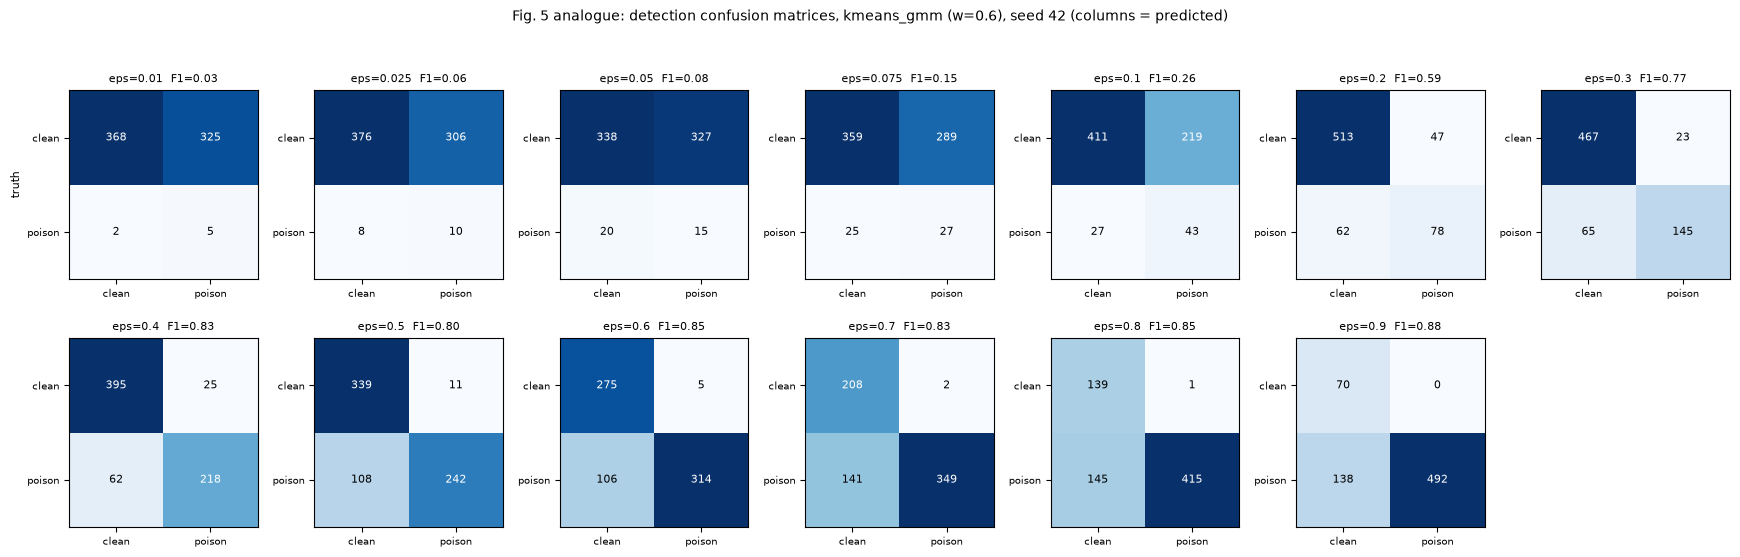

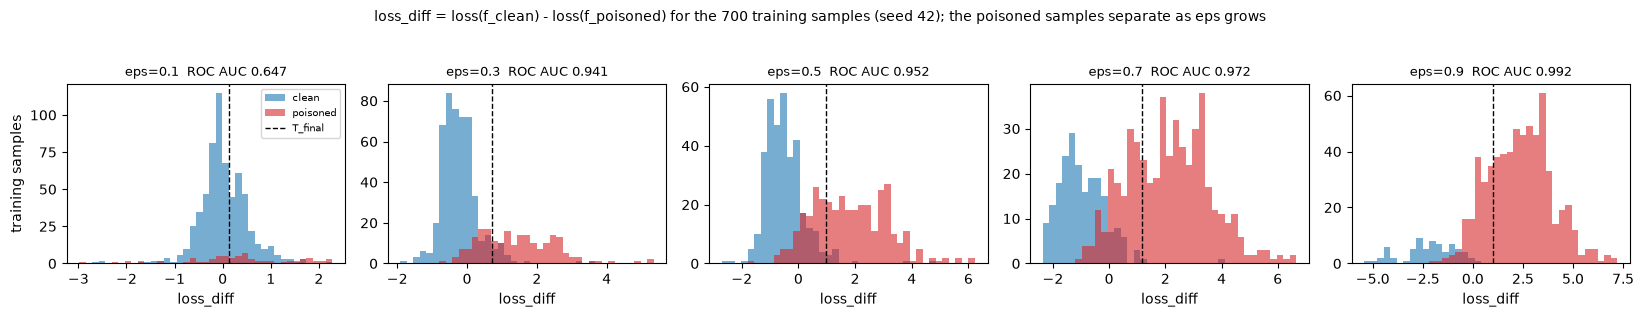

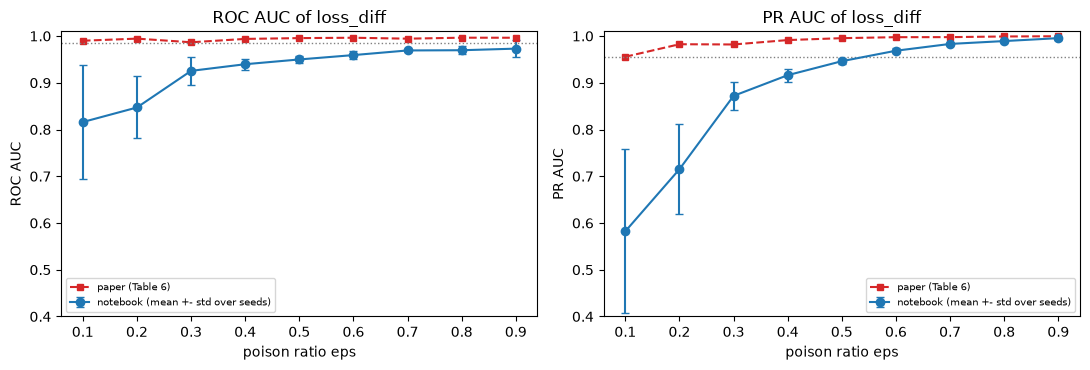

In [20]:
# ---- Fig. 5 analogue: detection confusion matrices (seed 42) ----
ncol = len(EPS_DET); nr = 1 if ncol <= 6 else 2; nc = int(np.ceil(ncol / nr))
fig, axes = plt.subplots(nr, nc, figsize=(2.5 * nc, 2.7 * nr)); axes = np.atleast_1d(axes).ravel()
for a_, e in zip(axes, EPS_DET):
    x = DET[(SEED, e)]; M = np.array([[x["tn"], x["fp"]], [x["fn"], x["tp"]]]); a_.imshow(M, cmap="Blues")
    for i in range(2):
        for j in range(2): a_.text(j, i, M[i, j], ha="center", va="center", fontsize=8, color="white" if M[i, j] > M.max() / 2 else "black")
    a_.set_title(f"eps={e}  F1={x['f1']:.2f}", fontsize=8); a_.set_xticks([0, 1]); a_.set_yticks([0, 1]); a_.set_xticklabels(["clean", "poison"], fontsize=7); a_.set_yticklabels(["clean", "poison"], fontsize=7)
for a_ in axes[ncol:]: a_.axis("off")
axes[0].set_ylabel("truth", fontsize=8); fig.suptitle(f"Fig. 5 analogue: detection confusion matrices, kmeans_gmm (w={W_TUNED}), seed {SEED} (columns = predicted)", y=1.03, fontsize=10)
plt.tight_layout(); plt.show()

# ---- the self-revealing signal: loss_diff of clean and poisoned samples as eps grows ----
show = [e for e in (0.1, 0.3, 0.5, 0.7, 0.9) if e in EPS_DET]
fig, axes = plt.subplots(1, len(show), figsize=(3.3 * len(show), 3.0), sharey=False)
for a_, e in zip(np.atleast_1d(axes), show):
    x = DET[(SEED, e)]; bins = np.linspace(x["score"].min(), x["score"].max(), 40)
    a_.hist(x["score"][~x["mask"]], bins=bins, alpha=0.6, color="tab:blue", label="clean"); a_.hist(x["score"][x["mask"]], bins=bins, alpha=0.6, color="tab:red", label="poisoned")
    a_.axvline(x["thr"], color="k", ls="--", lw=1, label="T_final"); a_.set_title(f"eps={e}  ROC AUC {x['roc_auc']:.3f}", fontsize=9); a_.set_xlabel("loss_diff")
np.atleast_1d(axes)[0].legend(fontsize=7); np.atleast_1d(axes)[0].set_ylabel("training samples")
fig.suptitle(f"loss_diff = loss(f_clean) - loss(f_poisoned) for the 700 training samples (seed {SEED}); the poisoned samples separate as eps grows", y=1.04, fontsize=10)
plt.tight_layout(); plt.show()

# ---- Fig. 6 analogue: AUC against eps ----
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, (col, pcol, name) in enumerate([("roc", 0, "ROC AUC"), ("pr", 2, "PR AUC")]):
    es = list(t6.index); mu = t6[f"{col}_mean"].values; sd = t6[f"{col}_std"].values
    ax[k].errorbar(es, mu, sd, fmt="o-", color="tab:blue", capsize=3, label="notebook (mean +- std over seeds)")
    ax[k].plot(es, [PAPER_T6[e][pcol] for e in es if e in PAPER_T6], "s--", color="tab:red", ms=4, label="paper (Table 6)")
    ax[k].axhline(0.986 if k == 0 else 0.956, color="gray", ls=":", lw=1); ax[k].set_xlabel("poison ratio eps"); ax[k].set_ylabel(name); ax[k].set_ylim(0.4, 1.01); ax[k].legend(fontsize=7); ax[k].set_title(name + " of loss_diff")
plt.tight_layout(); plt.show()


### 5.3 The sub-threshold regime (paper Table 5)

With 1 to 7.5 % poisoned samples the unsupervised two-cluster split is unstable, but the model also hardly suffers.


In [21]:
# ---- Table 5 analogue: sub-threshold regime (eps < 0.1), seed 42: F1 of the hybrid and of the plain 2-component-GMM threshold, Cohen's d, accuracy drop ----
rows = []
for eps in [e for e in EPS_DET if e < 0.1]:
    x = DET[(SEED, eps)]; s, mask = x["score"], x["mask"]
    gmm_only = detection_report(s, mask, thr_gmm(s))
    pv = PAPER_T5.get(eps, (np.nan,) * 5)
    rows.append(dict(eps=eps, N_poison=int(mask.sum()), kmeans_gmm_F1=x["f1"], paper_kmeans_gmm_F1=pv[1], GMM_2comp_F1=gmm_only["f1"], paper_GMM_F1=pv[2],
                     cohen_d=x["cohen_d"], paper_d=pv[3], acc_drop_pts=acc.loc[0.0, f"seed {SEED}"] - acc.loc[eps, f"seed {SEED}"], paper_drop=pv[4]))
t5 = pd.DataFrame(rows).set_index("eps")
print(f"Sub-threshold detection (seed {SEED})   [paper: Table 5]"); print(t5.round(3).to_string())
print("\nThe paper's argument: below eps = 0.05 detection is poor (few poisoned samples make the 2-cluster split unstable), but the accuracy loss is also negligible,")
print("so the failure is operationally benign.  Accuracy drop in this notebook is measured on a 300-image test set (one image = 0.33 points).")


Sub-threshold detection (seed 42)   [paper: Table 5]
       N_poison  kmeans_gmm_F1  paper_kmeans_gmm_F1  GMM_2comp_F1  paper_GMM_F1  cohen_d  paper_d  acc_drop_pts  paper_drop
eps                                                                                                                        
0.010         7          0.030                0.200         0.027         0.000   -0.023     2.38         0.000         0.0
0.025        18          0.060                0.588         0.058         0.632   -0.084     3.50        -0.333         1.7
0.050        35          0.080                0.714         0.082         0.722   -0.231     3.88         4.000         1.7
0.075        52          0.147                0.767         0.142         0.750    0.010     3.85         3.333         0.7

The paper's argument: below eps = 0.05 detection is poor (few poisoned samples make the 2-cluster split unstable), but the accuracy loss is also negligible,
so the failure is operationally benign.  Accu

## 6. Stage 2: quantum unlearning of the flagged samples (paper Sec. 3.4, 4.4)

Five methods repair the poisoned model using the flagged samples $D_f$ and the remaining samples $D_r$. **GA**: $L = CE_r - CE_f$. **SCRUB**: $L = CE_r + KL_r - KL_f$ with the poisoned model as frozen teacher. **CF**: $L = CE_r$ only.
**RGA**: ascent on $D_f$ with every gradient entry divided by the magnitude of the corresponding $D_r$ gradient. **Fisher forgetting**: one-shot dampening of the parameters that carry much more Fisher information for $D_f$ than for $D_r$.
The iterative methods run on the simulator with SPSA circuit gradients, batch 32.

**Budget.** The paper says "20 steps, batch 32, Adam lr 0.005". Taken literally this moves every circuit angle by at most $20\times 0.005 = 0.1$ rad, which barely changes our models (both columns are shown). Because the defender owns a clean reference set
(it trained $f_{clean}$ on it; those images are not in the victim's data), it can pick the budget of every method among three candidates on that set. The test set is never used for this choice.


In [22]:
UNLEARN_METHODS = ["GA", "SCRUB", "CF", "Fisher", "RGA"]

def ce_and_grad(logits, y):
    """Mean cross-entropy and its gradient with respect to the logits."""
    p = softmax(logits); loss = float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())
    g = p.copy(); g[np.arange(len(y)), y] -= 1.0
    return loss, g / len(y)

def kl_and_grad(teacher_logits, student_logits):
    """Mean KL(teacher || student) and its gradient with respect to the student logits."""
    pT, pS = softmax(teacher_logits), softmax(student_logits)
    kl = float((pT * (np.log(pT + 1e-12) - np.log(pS + 1e-12))).sum(1).mean())
    return kl, (pS - pT) / len(pT)

def method_loss(method, lf, yf, lr_, yr, tf=None, tr=None):
    """Scalar objective of an iterative unlearning method and its gradients with respect to the forget / retain logits.
    GA   : maximise CE on D_f while minimising it on D_r            L = CE_r - CE_f
    SCRUB: student diverges from the frozen teacher on D_f, stays close on D_r   L = CE_r + KL_r - KL_f
    CF   : continued fine-tuning on D_r only (D_f is discarded)     L = CE_r"""
    cr, gr = ce_and_grad(lr_, yr)
    if method == "CF":
        return cr, None, gr
    if method == "GA":
        cf, gf = ce_and_grad(lf, yf); return cr - cf, -gf, gr
    if method == "SCRUB":
        klr, gklr = kl_and_grad(tr, lr_); klf, gklf = kl_and_grad(tf, lf)
        return cr + klr - klf, -gklf, gr + gklr
    raise ValueError(method)

def per_sample_gradients(model, enc, y, h=1e-4):
    """Gradient of every sample's cross-entropy with respect to all trainable parameters (16 circuit angles, 16 weights, 4 biases).
    Circuit angles: central finite differences of the exact simulator (error ~1e-9); linear layer: analytic."""
    N = len(y); P = model.n_params; G = np.zeros((N, P + model.W.size + model.b.size))
    for k in range(P):
        e = np.zeros(P); e[k] = h
        G[:, k] = (ce_per_sample(model.logits(enc, model.theta + e), y) - ce_per_sample(model.logits(enc, model.theta - e), y)) / (2 * h)
    z = model.features(enc); p = softmax(z @ model.W + model.b); p[np.arange(N), y] -= 1.0
    G[:, P:P + model.W.size] = (z[:, :, None] * p[:, None, :]).reshape(N, -1); G[:, P + model.W.size:] = p
    return G

def fisher_forgetting(model0, enc, y, forget_idx, lam=FISHER_LAMBDA, alpha=FISHER_ALPHA):
    """Selective synaptic dampening (Foster et al.): diagonal empirical Fisher information on D_f and D_r; every parameter that matters much more
    for D_f than for D_r (F_f > alpha * F_r) is multiplied by beta = min(lam * F_r / F_f, 1).  One shot, no iterations."""
    m = model0.copy(); retain = np.setdiff1d(np.arange(len(y)), forget_idx)
    if len(forget_idx) == 0: return m
    G = per_sample_gradients(model0, enc, y)
    Ff, Fr = (G[forget_idx] ** 2).mean(0), (G[retain] ** 2).mean(0)
    params = np.concatenate([m.theta, m.W.ravel(), m.b])
    mask = Ff > alpha * Fr; beta = np.minimum(lam * Fr / (Ff + 1e-30), 1.0)
    params[mask] = params[mask] * beta[mask]
    P = m.n_params; m.theta = params[:P]; m.W = params[P:P + m.W.size].reshape(m.W.shape); m.b = params[P + m.W.size:]
    m.n_dampened = int(mask.sum())
    return m

def unlearn(method, model0, enc_tr, y_pois, forget_idx, steps=UNL_STEPS, batch=UNL_BATCH, lr=UNL_LR, seed=0, spsa_c=SPSA_C):
    """Stage 2: repair the poisoned model with the candidate forget set D_f (flagged samples) and the retain set D_r (everything else).
    The iterative methods run `steps` steps of batch `batch` with Adam (lr 0.005); the circuit gradient is a SPSA estimate (as in training),
    the linear layer uses its exact gradient.  Returns (model, wall-clock seconds, simulated circuit evaluations)."""
    t0 = time.time(); ev0 = EVAL_COUNTER[0]
    if method == "Fisher":
        m = fisher_forgetting(model0, enc_tr, y_pois, forget_idx); return m, time.time() - t0, EVAL_COUNTER[0] - ev0
    m = model0.copy(); teacher = model0
    retain_idx = np.setdiff1d(np.arange(len(y_pois)), forget_idx)
    if len(forget_idx) == 0 and method != "CF": return m, 0.0, 0
    r = np.random.default_rng(seed)
    opt_t, opt_w, opt_b = Adam(m.theta.shape, lr), Adam(m.W.shape, lr), Adam(m.b.shape, lr)
    for step in range(steps):
        bf = r.choice(forget_idx, min(batch, len(forget_idx)), replace=False) if method != "CF" else np.array([], dtype=int)
        br = r.choice(retain_idx, min(batch, len(retain_idx)), replace=False); nf = len(bf)
        e = enc_tr.take(np.concatenate([bf, br])); yf, yr = y_pois[bf], y_pois[br]
        delta = r.choice([-1.0, 1.0], m.theta.shape)
        def split(lg): return lg[:nf], lg[nf:]
        T = split(teacher.logits(e)) if method == "SCRUB" else (None, None)
        if method == "RGA":
            # RGA (Su et al.): forget-set gradient divided, parameter by parameter, by the magnitude of the retain-set gradient
            z = m.features(e); lf0, lr0 = split(z @ m.W + m.b)
            _, gf = ce_and_grad(lf0, yf); _, gr = ce_and_grad(lr0, yr)
            dWf, dWr = z[:nf].T @ gf, z[nf:].T @ gr; dbf, dbr = gf.sum(0), gr.sum(0)
            lp, lm = split(m.logits(e, m.theta + spsa_c * delta)), split(m.logits(e, m.theta - spsa_c * delta))
            gtf = (ce_and_grad(lp[0], yf)[0] - ce_and_grad(lm[0], yf)[0]) / (2 * spsa_c) * delta
            gtr = (ce_and_grad(lp[1], yr)[0] - ce_and_grad(lm[1], yr)[0]) / (2 * spsa_c) * delta
            eps_ = 1e-6
            g_theta, g_W, g_b = -gtf / (np.abs(gtr) + eps_), -dWf / (np.abs(dWr) + eps_), -dbf / (np.abs(dbr) + eps_)   # minus: ascent on D_f
        else:
            def L(theta):
                lf, lr_ = split(m.logits(e, theta))
                return method_loss(method, lf, yf, lr_, yr, T[0], T[1])[0]
            g_theta = (L(m.theta + spsa_c * delta) - L(m.theta - spsa_c * delta)) / (2 * spsa_c) * delta
            z = m.features(e); lf0, lr0 = split(z @ m.W + m.b)
            _, gf, gr = method_loss(method, lf0, yf, lr0, yr, T[0], T[1])
            g_W = z[nf:].T @ gr + (z[:nf].T @ gf if gf is not None else 0.0); g_b = gr.sum(0) + (gf.sum(0) if gf is not None else 0.0)
        m.theta = m.theta - opt_t.step(g_theta); m.W = m.W - opt_w.step(g_W); m.b = m.b - opt_b.step(g_b)
    return m, time.time() - t0, EVAL_COUNTER[0] - ev0

DEFENCE = {}
def defend(seed, eps, w=W_TUNED, methods=tuple(UNLEARN_METHODS)):
    """Whole framework for one poisoned victim: detect (stage 1), then unlearn the flagged samples with every method (stage 2).
    Every iterative method is run with each candidate budget of UNL_GRID (the first is the paper-literal 20 steps, lr 0.005); the defender keeps the
    candidate with the best accuracy on its own clean reference images -- these are not in the victim's training data, and the test set is never used."""
    key = (seed, round(eps, 4), w, tuple(methods))
    if key in DEFENCE: return DEFENCE[key]
    r = get_run(seed, eps); det = detect(seed, eps, w); d, e_tr, e_te, e_ref = encoded_sets(seed); e_tr.pauli()
    forget = np.where(det["flag"])[0]; res = {}
    for j, meth in enumerate(methods):
        sd = 1000 * seed + 17 * j + int(round(10 * eps)); cands = []
        for steps, lr_ in ([(0, 0.0)] if meth == "Fisher" else UNL_GRID):
            m, sec, ev = unlearn(meth, r["model"], e_tr, r["y_pois"], forget, steps=steps or UNL_STEPS, lr=lr_ or UNL_LR, seed=sd)
            cands.append(dict(steps=steps, lr=lr_, seconds=sec, evals=ev, val=float((m.predict(e_ref) == d["yref"]).mean()), acc=float((m.predict(e_te) == d["yte"]).mean())))
        best = int(np.argmax([c["val"] for c in cands]))                    # ties: the first candidate (paper-literal)
        res[meth] = dict(acc=cands[best]["acc"], steps=cands[best]["steps"], lr=cands[best]["lr"], acc_literal=cands[0]["acc"], val=cands[best]["val"],
                         seconds=cands[0]["seconds"], evals=cands[0]["evals"], candidates=cands)       # cost is always that of the literal 20-step run
    DEFENCE[key] = dict(det=det, unlearn=res, n_forget=len(forget), poisoned_acc=r["acc"])
    return DEFENCE[key]


### 6.1 Budget choice and unlearning runs


In [23]:
# ---- stage 2 on every poisoned victim.  For every method the defender tries the three budgets of UNL_GRID and keeps the one that does best on its clean reference images. ----
t0 = time.time()
for seed in SEEDS:
    for eps in EPS_DET:
        out = defend(seed, eps)
        print(f"seed {seed:3d} eps {eps:5.3f}: poisoned {100 * out['poisoned_acc']:5.1f} % | forget set {out['n_forget']:3d} | " +
              " ".join(f"{m}:{100 * v['acc']:.1f}" for m, v in out["unlearn"].items()) + f"   [{time.time() - t0:.0f} s]", flush=True)
TIME_UNLEARN = time.time() - t0
picks = pd.DataFrame([{"method": m, "budget": f"{v['steps']} steps, lr {v['lr']}"} for o in DEFENCE.values() for m, v in o["unlearn"].items() if m != "Fisher"])
print("\nbudget picked on the reference images (number of runs):"); print(picks.groupby(["method", "budget"]).size().unstack(fill_value=0).to_string())


seed  42 eps 0.010: poisoned  69.3 % | forget set 330 | GA:65.7 SCRUB:68.0 CF:69.3 Fisher:69.3 RGA:67.3   [32 s]


seed  42 eps 0.025: poisoned  69.7 % | forget set 316 | GA:67.0 SCRUB:69.7 CF:69.3 Fisher:69.7 RGA:66.0   [60 s]


seed  42 eps 0.050: poisoned  65.3 % | forget set 342 | GA:67.0 SCRUB:67.3 CF:67.3 Fisher:66.7 RGA:65.0   [82 s]


seed  42 eps 0.075: poisoned  66.0 % | forget set 316 | GA:64.7 SCRUB:65.7 CF:64.7 Fisher:17.7 RGA:64.3   [103 s]


seed  42 eps 0.100: poisoned  71.3 % | forget set 262 | GA:67.0 SCRUB:70.3 CF:68.7 Fisher:11.7 RGA:71.0   [122 s]


...

seed  24 eps 0.700: poisoned   8.7 % | forget set 349 | GA:26.0 SCRUB:32.0 CF:24.7 Fisher:8.7 RGA:26.7   [1120 s]


seed  24 eps 0.800: poisoned   7.7 % | forget set 297 | GA:20.3 SCRUB:32.7 CF:16.0 Fisher:21.3 RGA:24.0   [1146 s]


seed  24 eps 0.900: poisoned   4.7 % | forget set 299 | GA:14.3 SCRUB:6.3 CF:4.3 Fisher:4.7 RGA:25.0   [1178 s]



budget picked on the reference images (number of runs):


budget  100 steps, lr 0.025  20 steps, lr 0.005  20 steps, lr 0.025
method                                                             
CF                       21                  13                   5
GA                        7                  25                   7
RGA                      13                  23                   3
SCRUB                    20                  12                   7


### 6.2 Recovered accuracy and cost (paper Fig. 7, Table 7)


Clean-test accuracy (%) after unlearning the detected samples, mean over 3 seed(s)   [paper: Fig. 7]


       poisoned    GA  SCRUB    CF  Fisher   RGA  clean baseline
eps                                                             
0.010      67.2  67.1   67.8  68.1    43.2  67.3            67.4
0.025      66.9  67.6   68.6  68.9    42.1  65.9            67.4
0.050      68.1  68.3   68.8  69.3    43.6  68.6            67.4
0.075      67.9  67.2   67.8  67.4    22.8  67.7            67.4
0.100      67.0  65.0   65.9  66.9    21.4  66.4            67.4
0.200      66.6  68.6   67.8  68.9    19.9  68.1            67.4
0.300      53.8  62.4   65.7  63.0    30.7  62.1            67.4
0.400      43.1  47.9   60.8  58.3    31.7  47.0            67.4
0.500      27.6  34.8   51.9  54.7    30.9  36.7            67.4
0.600      19.7  30.9   44.4  40.4    20.6  28.6            67.4
0.700      10.7  25.3   44.8  32.1    14.3  28.9            67.4
0.800       5.4  25.0   36.3  27.2    10.0  24.2            67.4
0.900       4.1  20.3   27.3  22.1     4.1  26.0            67.4

Same, with the paper-li

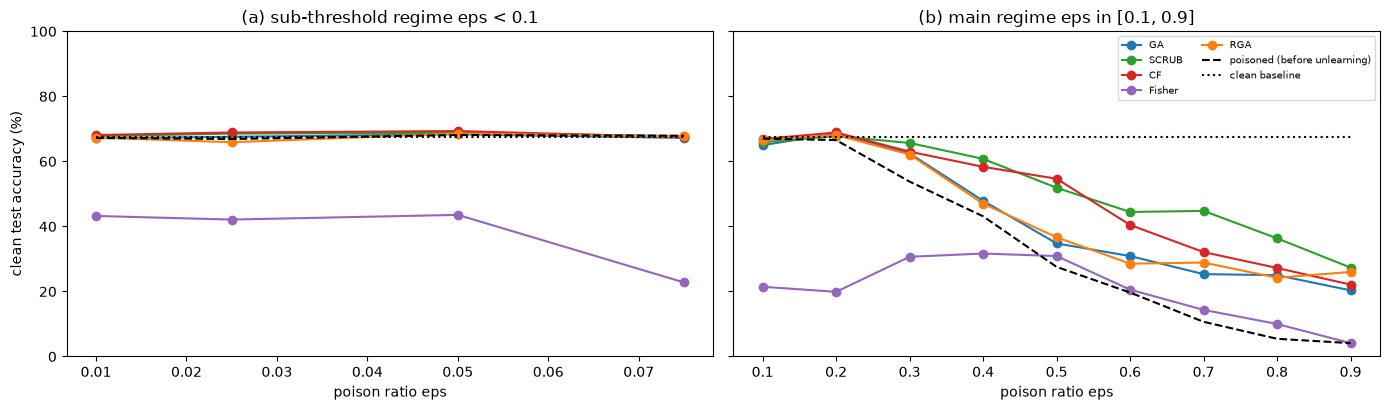


Cost of the five methods   [paper: Table 7]
        steps  evals_per_step_analytic  mean_seconds  measured_sample_evals  paper_seconds paper_formula  seconds_per_step  per-step time vs GA  evals vs GA  paper time vs GA
method                                                                                                                                                                        
GA         20                       64         0.891                 3840.0         3059.3           2TB             0.045                1.000        1.000             1.000
SCRUB      20                      128         1.229                 5120.0         3175.7           4TB             0.061                1.380        1.333             1.038
CF         20                       32         0.785                 1920.0         1578.4            TB             0.039                0.882        0.500             0.516
Fisher      0                      700         2.214                23100.0     

In [24]:
def mean_acc(eps, meth):
    return 100 * np.mean([DEFENCE[(s, round(eps, 4), W_TUNED, tuple(UNLEARN_METHODS))]["unlearn"][meth]["acc"] for s in SEEDS])
def mean_acc_literal(eps, meth):
    return 100 * np.mean([DEFENCE[(s, round(eps, 4), W_TUNED, tuple(UNLEARN_METHODS))]["unlearn"][meth]["acc_literal"] for s in SEEDS])

rec = pd.DataFrame({"poisoned": [acc.loc[e, "mean"] for e in EPS_DET], **{m: [mean_acc(e, m) for e in EPS_DET] for m in UNLEARN_METHODS}}, index=EPS_DET)
rec["clean baseline"] = CLEAN_ACC; rec.index.name = "eps"
print(f"Clean-test accuracy (%) after unlearning the detected samples, mean over {len(SEEDS)} seed(s)   [paper: Fig. 7]"); print(rec.round(1).to_string())
lit = pd.DataFrame({m: [mean_acc_literal(e, m) for e in EPS_DET] for m in UNLEARN_METHODS if m != "Fisher"}, index=EPS_DET); lit.index.name = "eps"
print("\nSame, with the paper-literal budget (20 steps, batch 32, Adam lr 0.005) for every iterative method:"); print(lit.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
cols = {"GA": "tab:blue", "SCRUB": "tab:green", "CF": "tab:red", "Fisher": "tab:purple", "RGA": "tab:orange"}
for a_, sub, ttl in [(axes[0], [e for e in EPS_DET if e < 0.1], "(a) sub-threshold regime eps < 0.1"), (axes[1], [e for e in EPS_DET if e >= 0.1], "(b) main regime eps in [0.1, 0.9]")]:
    if not sub: a_.set_title(ttl + " (not run)"); continue
    for m in UNLEARN_METHODS: a_.plot(sub, rec.loc[sub, m], "o-", color=cols[m], label=m)
    a_.plot(sub, rec.loc[sub, "poisoned"], "k--", label="poisoned (before unlearning)"); a_.plot(sub, rec.loc[sub, "clean baseline"], "k:", label="clean baseline")
    a_.set_xlabel("poison ratio eps"); a_.set_title(ttl); a_.set_ylim(0, 100)
axes[0].set_ylabel("clean test accuracy (%)"); axes[1].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

# ---- Table 7 analogue: cost.  The paper's seconds come from PennyLane's default.mixed on a Sapphire Rapids CPU; ours from a NumPy simulator, so we compare
#      the circuit-evaluation counts and the RATIOS, not the seconds.  Counts per step: GA 2B, SCRUB 4B, CF B, RGA 2B; Fisher n (one pass over all samples). ----
N_TR = 700
analytic = {"GA": 2 * UNL_BATCH, "SCRUB": 4 * UNL_BATCH, "CF": UNL_BATCH, "RGA": 2 * UNL_BATCH}
rows = []
for m in UNLEARN_METHODS:
    xs = [DEFENCE[(s, round(e, 4), W_TUNED, tuple(UNLEARN_METHODS))]["unlearn"][m] for s in SEEDS for e in EPS_DET]
    steps = UNL_STEPS if m != "Fisher" else 0                       # cost is always measured on the paper-literal 20-step run
    rows.append(dict(method=m, steps=steps, evals_per_step_analytic=analytic.get(m, N_TR), mean_seconds=np.mean([x["seconds"] for x in xs]),
                     measured_sample_evals=np.mean([x["evals"] for x in xs]), paper_seconds=PAPER_T7[m][0], paper_formula=PAPER_T7[m][1]))
cost = pd.DataFrame(rows).set_index("method")
cost["seconds_per_step"] = cost.mean_seconds / cost.steps.replace(0, np.nan)
ga_sec = cost.loc["GA", "seconds_per_step"]; ga_paper = PAPER_T7["GA"][0]
cost["per-step time vs GA"] = cost.seconds_per_step / ga_sec
cost["evals vs GA"] = cost.measured_sample_evals / cost.loc["GA", "measured_sample_evals"]
cost["paper time vs GA"] = cost.paper_seconds / ga_paper
print("\nCost of the five methods   [paper: Table 7]"); print(cost.round(3).to_string())
print("\nNote: circuit evaluations per step -- GA 2B (forget + retain batch), SCRUB 4B (student and teacher on both), CF B, RGA 2B, Fisher n -- are properties of the algorithms;")
print("the SPSA gradient adds the same 2 extra evaluations to every iterative method, so the ratios are unchanged.")


### 6.3 Poisoned versus unlearned accuracy (paper Table 8) and the 10-point claim


In [25]:
rows = []
for eps, (pa, kg, pbest, pmeth) in PAPER_T8.items():
    if eps == 0.0:
        rows.append(dict(eps=eps, poisoned_acc=CLEAN_ACC, paper_poisoned=pa, Kundu_Ghosh=kg, best_after_unlearning="-", paper_best="-")); continue
    if eps not in EPS_DET: continue
    best_m = max(UNLEARN_METHODS, key=lambda m: mean_acc(eps, m))
    rows.append(dict(eps=eps, poisoned_acc=acc.loc[eps, "mean"], paper_poisoned=pa, Kundu_Ghosh=kg, best_after_unlearning=f"{mean_acc(eps, best_m):.1f} ({best_m})", paper_best=f"{pbest} ({pmeth})"))
t8 = pd.DataFrame(rows).set_index("eps")
print("Poisoned accuracy and best post-unlearning accuracy   [paper: Table 8]"); print(t8.round(1).to_string())

# recovery to within 10 points of the clean baseline (paper abstract: GA, SCRUB and CF for eps <= 0.5)
gap = pd.DataFrame({m: [CLEAN_ACC - mean_acc(e, m) for e in EPS_DET] for m in UNLEARN_METHODS}, index=EPS_DET); gap.index.name = "eps"
print("\nGap to the clean baseline after unlearning (points; a method 'recovers' when the gap is <= 10):"); print(gap.round(1).to_string())
within = {m: all(gap.loc[e, m] <= 10 for e in EPS_DET if 0.1 <= e <= 0.5) for m in UNLEARN_METHODS}
print("\nwithin 10 points for all eps in [0.1, 0.5]:", within)


Poisoned accuracy and best post-unlearning accuracy   [paper: Table 8]
     poisoned_acc  paper_poisoned  Kundu_Ghosh best_after_unlearning    paper_best
eps                                                                               
0.0          67.4            83.0         81.3                     -             -
0.1          67.0            80.7         77.3             66.9 (CF)     84.7 (GA)
0.3          53.8            76.7         69.3          65.7 (SCRUB)  84.3 (SCRUB)
0.5          27.6            39.3         20.9             54.7 (CF)     78.0 (CF)
0.7          10.7             5.3          5.6          44.8 (SCRUB)     59.3 (GA)

Gap to the clean baseline after unlearning (points; a method 'recovers' when the gap is <= 10):
         GA  SCRUB    CF  Fisher   RGA
eps                                   
0.010   0.3   -0.3  -0.7    24.2   0.1
0.025  -0.1   -1.1  -1.4    25.3   1.6
0.050  -0.9   -1.3  -1.9    23.9  -1.1
0.075   0.2   -0.3   0.0    44.7  -0.2
0.100   2.4    1.

## 7. A label-free defender on held-out seeds (paper appendix A.3)

To check that $w = 0.6$ (tuned on seeds 42, 1, 24 against the ground truth) does not flatter the results, the paper repeats the defence on seeds that were not used to select $w$, with the neutral value $w = 0.5$, no knowledge of $\varepsilon$, and CF as the only unlearning method.


held-out seed 101 eps 0.1: poisoned 81.3 % -> CF 79.0 %  [129 s]


held-out seed 101 eps 0.2: poisoned 61.7 % -> CF 64.7 %  [162 s]


held-out seed 101 eps 0.3: poisoned 72.3 % -> CF 71.3 %  [192 s]


held-out seed 101 eps 0.4: poisoned 43.7 % -> CF 54.3 %  [225 s]


held-out seed 101 eps 0.5: poisoned 25.7 % -> CF 27.7 %  [256 s]


...

held-out seed 303 eps 0.6: poisoned 32.7 % -> CF 52.7 %  [956 s]


held-out seed 303 eps 0.7: poisoned 8.0 % -> CF 51.7 %  [971 s]


held-out seed 303 eps 0.8: poisoned 5.0 % -> CF 48.3 %  [984 s]


held-out seed 303 eps 0.9: poisoned 2.0 % -> CF 40.0 %  [996 s]



Held-out defender (seeds [101, 202, 303], w = 0.5)   [paper: Table 12, Fig. 10]
            ROC_AUC       paper_ROC          PR_AUC        paper_PR  poisoned_acc  after_CF
eps                                                                                        
0.1  0.791 +- 0.080  0.934 +- 0.029  0.547 +- 0.230  0.858 +- 0.049          65.2      69.0
0.2  0.906 +- 0.028  0.957 +- 0.005  0.801 +- 0.056  0.927 +- 0.030          57.7      57.7
0.3  0.926 +- 0.035  0.962 +- 0.012  0.883 +- 0.036  0.950 +- 0.010          58.6      60.1
0.4  0.932 +- 0.034  0.975 +- 0.004  0.922 +- 0.030  0.972 +- 0.001          43.8      55.2
0.5  0.957 +- 0.019  0.974 +- 0.006  0.961 +- 0.015  0.979 +- 0.005          29.3      45.7
0.6  0.961 +- 0.021  0.980 +- 0.003  0.973 +- 0.012  0.988 +- 0.002          21.4      43.2
0.7  0.966 +- 0.016  0.988 +- 0.002  0.983 +- 0.006  0.995 +- 0.000           5.9      43.8
0.8  0.974 +- 0.017  0.985 +- 0.007  0.993 +- 0.004  0.996 +- 0.002           4.7      37.7

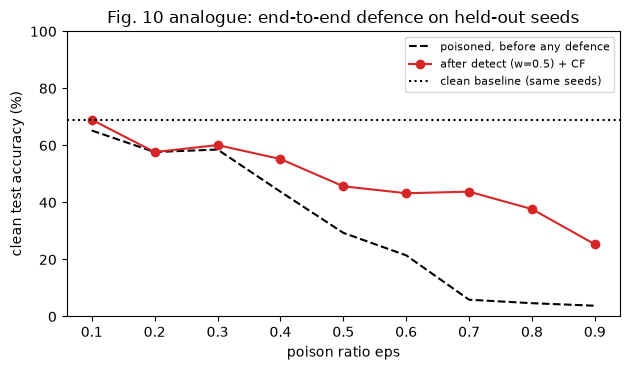

In [26]:
# Appendix A.3: a label-free defender on seeds that were never used to choose w.  The mixing weight is fixed a priori at 0.5, the poison ratio is unknown,
# ROC/PR AUC are reported for eps in [0.1, 0.9] and the only unlearning method is CF (eps up to 0.7).
t0 = time.time(); H = {}
for seed in HELDOUT_SEEDS:
    get_reference(seed); get_run(seed, 0.0)
    for eps in EPS_HELDOUT:
        H[(seed, eps)] = defend(seed, eps, w=W_APRIORI, methods=("CF",))
        print(f"held-out seed {seed} eps {eps}: poisoned {100 * H[(seed, eps)]['poisoned_acc']:.1f} % -> CF {100 * H[(seed, eps)]['unlearn']['CF']['acc']:.1f} %  [{time.time() - t0:.0f} s]", flush=True)
TIME_HELDOUT = time.time() - t0

rows = []
for eps in EPS_HELDOUT:
    ra = np.array([H[(s, eps)]["det"]["roc_auc"] for s in HELDOUT_SEEDS]); pa = np.array([H[(s, eps)]["det"]["pr_auc"] for s in HELDOUT_SEEDS]); pv = PAPER_T12.get(eps, (np.nan,) * 4)
    rows.append(dict(eps=eps, ROC_AUC=f"{ra.mean():.3f} +- {ra.std():.3f}", paper_ROC=f"{pv[0]:.3f} +- {pv[1]:.3f}", PR_AUC=f"{pa.mean():.3f} +- {pa.std():.3f}", paper_PR=f"{pv[2]:.3f} +- {pv[3]:.3f}",
                     poisoned_acc=100 * np.mean([H[(s, eps)]["poisoned_acc"] for s in HELDOUT_SEEDS]), after_CF=100 * np.mean([H[(s, eps)]["unlearn"]["CF"]["acc"] for s in HELDOUT_SEEDS]),
                     roc_mean=ra.mean(), pr_mean=pa.mean()))
t12 = pd.DataFrame(rows).set_index("eps")
print(f"\nHeld-out defender (seeds {HELDOUT_SEEDS}, w = {W_APRIORI})   [paper: Table 12, Fig. 10]"); print(t12.drop(columns=["roc_mean", "pr_mean"]).round(1).to_string())
print(f"\nmean ROC AUC over eps: {t12.roc_mean.mean():.3f} (paper 0.97), mean PR AUC: {t12.pr_mean.mean():.3f} (paper 0.96)")
clean_h = np.mean([100 * get_run(s, 0.0)["acc"] for s in HELDOUT_SEEDS])
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(t12.index, t12.poisoned_acc, "k--", label="poisoned, before any defence"); ax.plot(t12.index, t12.after_CF, "o-", color="tab:red", label=f"after detect (w={W_APRIORI}) + CF")
ax.axhline(clean_h, color="k", ls=":", label="clean baseline (same seeds)"); ax.set_xlabel("poison ratio eps"); ax.set_ylabel("clean test accuracy (%)"); ax.set_ylim(0, 100); ax.legend(fontsize=8)
ax.set_title("Fig. 10 analogue: end-to-end defence on held-out seeds"); plt.tight_layout(); plt.show()


## 8. Is the framework quantum-specific? Classical baselines (paper Sec. 4.6)

The detection signal is a classical cross-entropy and unlearning is ordinary parameter updating, so the pipeline should transfer to classical networks. The first cell trains an SVC (RBF) and a random forest on **exactly** the QNN's 8 angles and
the QNN's poisoned labels. The second repeats the whole pipeline on two small MLPs with a classical analogue of QUID (farthest class by Euclidean distance).


In [27]:
EPOCHS_MLP = 12 if FAST_MODE else 30        # CHOICE: the paper gives no training budget for the MLPs; the QNN's is reused

class MLP(nn.Module):
    """784 -> 16 -> 4 -> 4 (raw pixels) or 8 -> 16 -> 4 -> 4 (auto-encoder latent), ReLU between the layers (paper Sec. 4.6)."""
    def __init__(self, d_in):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, 16), nn.ReLU(), nn.Linear(16, 4), nn.ReLU(), nn.Linear(4, 4))
    def forward(self, x):
        return self.net(x)

def mlp_inputs(d, kind):
    """Inputs of the classical models: raw pixels in [0, 1], or the 8 scaled auto-encoder numbers (standardised with training statistics)."""
    if kind == "raw":
        f = lambda a: a.reshape(len(a), -1).astype(np.float32) / 255.0
        return f(d["img_tr"]), f(d["img_te"]), f(d["img_ref"])
    mu, sd = d["ftr"].mean(0), d["ftr"].std(0) + 1e-9
    f = lambda a: ((a - mu) / sd).astype(np.float32)
    return f(d["ftr"]), f(d["fte"]), f(d["fref"])

def classical_quid_labels(X, y_true, idx, classes=(0, 1, 2, 3)):
    """Classical analogue of QUID (paper Sec. 4.6): the farthest class (largest mean Euclidean distance in the model's input space)."""
    A, sq = X[idx].astype(np.float64), (X.astype(np.float64) ** 2).sum(1)
    D = np.sqrt(np.maximum((A ** 2).sum(1)[:, None] + sq[None, :] - 2 * A @ X.astype(np.float64).T, 0)); D[np.arange(len(idx)), idx] = np.nan
    return np.array(classes)[np.stack([np.nanmean(D[:, y_true == c], axis=1) for c in classes], axis=1).argmax(1)]

def train_mlp(X, y, seed, epochs=EPOCHS_MLP, lr=0.01, batch=32):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    m = MLP(X.shape[1]); opt = torch.optim.Adam(m.parameters(), lr=lr); Xt, yt = torch.tensor(X), torch.tensor(y, dtype=torch.long)
    for ep in range(epochs):
        perm = torch.randperm(len(Xt), generator=g)
        for s in range(0, len(Xt), batch):
            idx = perm[s:s + batch]; opt.zero_grad(); F.cross_entropy(m(Xt[idx]), yt[idx]).backward(); opt.step()
    return m.eval()

def mlp_acc(m, X, y):
    with torch.no_grad(): return float((m(torch.tensor(X)).argmax(1).numpy() == y).mean())

def mlp_losses(m, X, y):
    with torch.no_grad(): return F.cross_entropy(m(torch.tensor(X)), torch.tensor(y, dtype=torch.long), reduction="none").numpy()

def unlearn_mlp(method, model0, X, y, forget_idx, steps, batch, lr, seed):
    """CF / GA / SCRUB on a classical network with autograd: the same objectives, steps, batch size and Adam learning rate as for the QNN."""
    m = copy.deepcopy(model0).train(); teacher = copy.deepcopy(model0).eval(); opt = torch.optim.Adam(m.parameters(), lr=lr)
    retain = np.setdiff1d(np.arange(len(y)), forget_idx); r = np.random.default_rng(seed)
    Xt, yt = torch.tensor(X), torch.tensor(y, dtype=torch.long)
    if len(forget_idx) == 0 and method != "CF": return m.eval()
    for _ in range(steps):
        br = torch.tensor(r.choice(retain, min(batch, len(retain)), replace=False)); lr_ = m(Xt[br]); loss = F.cross_entropy(lr_, yt[br])
        if method != "CF":
            bf = torch.tensor(r.choice(forget_idx, min(batch, len(forget_idx)), replace=False)); lf = m(Xt[bf])
            if method == "GA": loss = loss - F.cross_entropy(lf, yt[bf])
            else:
                with torch.no_grad(): tf, tr = teacher(Xt[bf]), teacher(Xt[br])
                kl = lambda t, s: F.kl_div(F.log_softmax(s, 1), F.softmax(t, 1), reduction="batchmean")
                loss = loss + kl(tr, lr_) - kl(tf, lf)
        opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

CLASSICAL = {}
def classical_run(seed, eps, kind, w=W_TUNED):
    """Whole pipeline on an MLP: classical QUID relabelling, poisoned model, clean reference model, loss_diff detection, CF / GA / SCRUB, full retraining."""
    key = (seed, round(eps, 4), kind)
    if key in CLASSICAL: return CLASSICAL[key]
    d = get_data(seed); Xtr, Xte, Xref = mlp_inputs(d, kind); N = len(d["ytr"]); npois = int(round(eps * N))
    idx = np.random.default_rng(10_000 + seed).permutation(N)[:npois]; y_p = d["ytr"].copy(); mask = np.zeros(N, dtype=bool)
    if npois: y_p[idx] = classical_quid_labels(Xtr, d["ytr"], idx); mask[idx] = True
    pois = train_mlp(Xtr, y_p, seed); ref = train_mlp(Xref, d["yref"], seed + 500)
    s = mlp_losses(ref, Xtr, y_p) - mlp_losses(pois, Xtr, y_p)
    out = dict(acc=mlp_acc(pois, Xte, d["yte"]), ref_acc=mlp_acc(ref, Xte, d["yte"]))
    if 0 < npois < N:
        out["roc_auc"] = float(roc_auc_score(mask, s)); det = detection_report(s, mask, hybrid_threshold(s, w)); out["f1"] = det["f1"]
        forget = np.where(det["flag"])[0]
        for j, meth in enumerate(["CF", "GA", "SCRUB"]):
            out[meth] = mlp_acc(unlearn_mlp(meth, pois, Xtr, y_p, forget, UNL_STEPS, UNL_BATCH, UNL_LR, seed + j), Xte, d["yte"])
        keep = np.setdiff1d(np.arange(N), forget)
        out["retrain"] = mlp_acc(train_mlp(Xtr[keep], y_p[keep], seed + 77), Xte, d["yte"])
    CLASSICAL[key] = out
    return out


Test accuracy (%) with the same inputs and the same QUID-poisoned labels, mean over seeds:
      QNN  SVC_rbf  RandomForest
eps                             
0.0  67.4     93.0          91.3
0.1  67.0     92.7          90.4
0.3  53.8     89.2          78.3
0.5  27.6     53.6          46.4
0.7  10.7      8.7          13.8
0.9   4.1      2.7           2.8


raw: done [990 s]


latent: done [2944 s]



Classical MLPs, mean over 6 seeds (accuracies in %):
              acc  roc_auc     CF     GA  SCRUB  retrain
kind   eps                                              
latent 0.0  93.28      NaN    NaN    NaN    NaN      NaN
       0.1  92.67     0.98  92.67  89.89  91.56    92.39
       0.2  87.28     0.99  88.61  84.78  87.28    92.39
       0.3  87.28     0.99  90.78  87.33  89.89    91.89
       0.4  74.94     1.00  89.33  87.28  88.83    90.67
       0.5  50.50     1.00  81.33  75.33  78.22    88.17
       0.6  24.94     1.00  64.89  62.06  62.33    79.00
       0.7  10.17     1.00  39.39  43.44  39.06    52.28
       0.8   3.00     1.00  21.72  31.78  28.06    41.39
       0.9   0.89     1.00  11.67  24.61  20.50    18.28
raw    0.0  94.83      NaN    NaN    NaN    NaN      NaN
       0.1  87.33     0.98  90.94  66.11  79.33    93.17
       0.2  79.83     0.99  87.00  63.61  76.72    91.72
       0.3  72.11     0.99  82.83  63.78  67.61    91.83
       0.4  62.94     0.99  79.00 

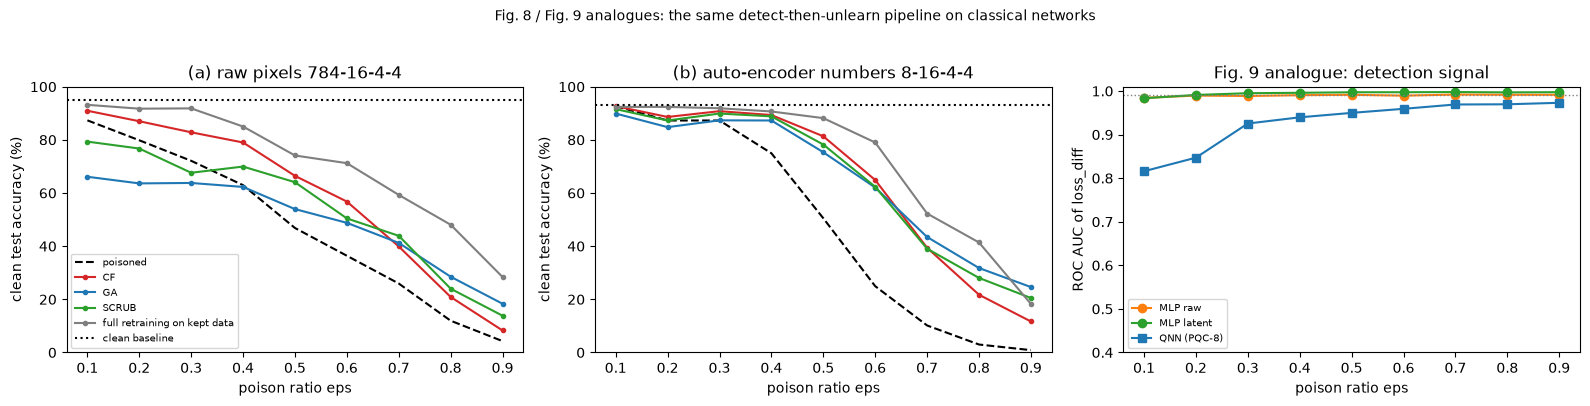

In [28]:
# ---- (1) classical models on exactly the QNN's inputs (the 8 scaled angles) and exactly the QNN's poisoned labels ----
rows = []
for seed in SEEDS:
    dd = get_data(seed)
    for eps in [e for e in (0.0, 0.1, 0.3, 0.5, 0.7, 0.9) if e in EPS_ALL]:
        y_p = get_run(seed, eps)["y_pois"]
        rows.append(dict(seed=seed, eps=eps, QNN=100 * get_run(seed, eps)["acc"],
                         SVC_rbf=100 * SVC(random_state=seed).fit(dd["ftr"], y_p).score(dd["fte"], dd["yte"]),
                         RandomForest=100 * RandomForestClassifier(n_estimators=100, random_state=seed).fit(dd["ftr"], y_p).score(dd["fte"], dd["yte"])))
bl = pd.DataFrame(rows)
print("Test accuracy (%) with the same inputs and the same QUID-poisoned labels, mean over seeds:")
print(bl.groupby("eps")[["QNN", "SVC_rbf", "RandomForest"]].mean().round(1).to_string())

# ---- (2) Section 4.6: the same pipeline on classical MLPs (raw pixels 784-16-4-4 and auto-encoder numbers 8-16-4-4) ----
t0 = time.time(); rows = []
for kind in ("raw", "latent"):
    for seed in CLASSICAL_SEEDS:
        for eps in [0.0] + EPS_MAIN:
            r = classical_run(seed, eps, kind); rows.append(dict(kind=kind, seed=seed, eps=eps, **r))
    print(f"{kind}: done [{time.time() - t0:.0f} s]", flush=True)
cl = pd.DataFrame(rows); TIME_CLASSICAL = time.time() - t0
g = cl.groupby(["kind", "eps"])[["acc", "roc_auc", "CF", "GA", "SCRUB", "retrain"]].mean() * 100
g["roc_auc"] /= 100
print(f"\nClassical MLPs, mean over {len(CLASSICAL_SEEDS)} seeds (accuracies in %):"); print(g.round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
for a_, kind, ttl in [(axes[0], "raw", "(a) raw pixels 784-16-4-4"), (axes[1], "latent", "(b) auto-encoder numbers 8-16-4-4")]:
    gk = g.loc[kind]; es = [e for e in gk.index if e > 0]
    a_.plot(es, gk.loc[es, "acc"], "k--", label="poisoned")
    for m_, c_ in [("CF", "tab:red"), ("GA", "tab:blue"), ("SCRUB", "tab:green"), ("retrain", "tab:gray")]: a_.plot(es, gk.loc[es, m_], "o-", ms=3, color=c_, label=m_ if m_ != "retrain" else "full retraining on kept data")
    a_.axhline(gk.loc[0.0, "acc"], color="k", ls=":", label="clean baseline"); a_.set_title(ttl); a_.set_xlabel("poison ratio eps"); a_.set_ylabel("clean test accuracy (%)"); a_.set_ylim(0, 100)
axes[0].legend(fontsize=7)
for kind, c_ in [("raw", "tab:orange"), ("latent", "tab:green")]:
    es = [e for e in g.loc[kind].index if e > 0]; axes[2].plot(es, g.loc[kind].loc[es, "roc_auc"], "o-", color=c_, label=f"MLP {kind}")
axes[2].plot(list(t6.index), t6.roc_mean, "s-", color="tab:blue", label="QNN (PQC-8)"); axes[2].axhline(0.99, color="gray", ls=":", lw=1)
axes[2].set_ylim(0.4, 1.01); axes[2].set_xlabel("poison ratio eps"); axes[2].set_ylabel("ROC AUC of loss_diff"); axes[2].set_title("Fig. 9 analogue: detection signal"); axes[2].legend(fontsize=7)
fig.suptitle("Fig. 8 / Fig. 9 analogues: the same detect-then-unlearn pipeline on classical networks", y=1.03, fontsize=10); plt.tight_layout(); plt.show()


## 9. Appendix ablations (paper appendix A.1, A.2)

These need no new training: they reuse the stored `loss_diff` and `ref_loss` scores of the victims trained above. Table 9 ranks samples with $S = w\cdot\text{loss\_diff} + (1-w)\cdot\text{ref\_loss}$ (both z-scored) and flags the top $\varepsilon N$ (an oracle rule that knows $\varepsilon$);
Table 11 sweeps the weight $w$ of the hybrid threshold; Table 10 compares unsupervised threshold methods by regime.


In [29]:
# Appendix A.1 / A.2: ablations that only need the stored scores of the victims already trained above (no extra training).
EPS_APP = [e for e in EPS_DET if 0.1 <= e <= 0.9]
def zs(a): return (a - a.mean()) / (a.std() + 1e-12)

# ---- Table 9: Oracle top-eps*N thresholding of  S = w * loss_diff + (1 - w) * ref_loss  (w = weight of loss_diff, signals z-scored: CHOICE) ----
rows = []
for w in (1.0, 0.75, 0.5, 0.25, 0.0):
    f1s = []
    for s in SEEDS:
        for e in EPS_APP:
            x = DET[(s, e)]; S = w * zs(x["score"]) + (1 - w) * zs(x["ref_loss"]); k = int(round(e * len(S)))
            flag = np.zeros(len(S), dtype=bool); flag[np.argsort(-S)[:k]] = True
            tp = (flag & x["mask"]).sum(); f1s.append(2 * tp / (flag.sum() + x["mask"].sum()))
    rows.append(dict(w_loss_diff=w, avg_F1=np.mean(f1s), paper_avg_F1=PAPER_T9[w]))
t9 = pd.DataFrame(rows).set_index("w_loss_diff")
print("Signal fusion with the oracle top-eps*N rule   [paper: Table 9]"); print(t9.round(4).to_string())

# ---- Table 11: mixing weight w of the hybrid threshold (average F1 over eps in [0.1, 0.9] and seeds) ----
rows = []
for w in np.round(np.arange(0, 1.01, 0.1), 1):
    f_km, f_ot = [], []
    for s in SEEDS:
        for e in EPS_APP:
            x = DET[(s, e)]; sc = x["score"]
            f_km.append(detection_report(sc, x["mask"], hybrid_threshold(sc, w, "kmeans"))["f1"]); f_ot.append(detection_report(sc, x["mask"], hybrid_threshold(sc, w, "otsu"))["f1"])
    rows.append(dict(w=w, kmeans_gmm=np.mean(f_km), otsu_gmm=np.mean(f_ot), paper_kmeans_gmm=PAPER_T11[float(w)]))
t11 = pd.DataFrame(rows).set_index("w")
print("\nMixing weight w of Eq. (1)   [paper: Table 11]"); print(t11.round(4).to_string())
W_BEST = float(t11.kmeans_gmm.idxmax()); print(f"best w here: {W_BEST} (paper: 0.6)")

# ---- Table 10: unsupervised threshold methods, F1 by poison regime ----
REGIMES = {"Low (0.1-0.2)": (0.1, 0.2), "Mid (0.3-0.6)": (0.3, 0.6), "High (0.7-0.8)": (0.7, 0.8), "Edge (0.9)": (0.9, 0.9), "Overall (0.1-0.9)": (0.1, 0.9)}
methods = {"kmeans_gmm (w=0.6)": lambda sc: hybrid_threshold(sc, 0.6, "kmeans"), "otsu_gmm (w=0.6)": lambda sc: hybrid_threshold(sc, 0.6, "otsu"),
           "Otsu 1-D": thr_otsu, "K-Means 1-D": thr_kmeans, "GMM 2-comp": thr_gmm}
rows = []
for name, fn in methods.items():
    row = {"method": name}
    for reg, (lo, hi) in REGIMES.items():
        es = [e for e in EPS_APP if lo - 1e-9 <= e <= hi + 1e-9]
        row[reg] = np.mean([detection_report(DET[(s, e)]["score"], DET[(s, e)]["mask"], fn(DET[(s, e)]["score"]))["f1"] for s in SEEDS for e in es]) if es else np.nan
    rows.append(row)
t10 = pd.DataFrame(rows).set_index("method")
PAPER_T10_OVERALL = {"kmeans_gmm (w=0.6)": 0.9316, "otsu_gmm (w=0.6)": 0.9293, "Otsu 1-D": 0.8698, "K-Means 1-D": 0.8661, "GMM 2-comp": 0.8332}   # mean of the three seeds in Table 10 (Kneedle: 0.6385, not implemented)
t10["paper overall (mean of 3 seeds)"] = pd.Series(PAPER_T10_OVERALL)
print("\nThreshold methods, F1 by regime (mean over seeds)   [paper: Table 10; Kneedle is not implemented here]"); print(t10.round(4).to_string())


Signal fusion with the oracle top-eps*N rule   [paper: Table 9]
             avg_F1  paper_avg_F1
w_loss_diff                      
1.00         0.8418        0.9604
0.75         0.8472        0.9605
0.50         0.8551        0.9573
0.25         0.8546        0.9516
0.00         0.8526        0.9445



Mixing weight w of Eq. (1)   [paper: Table 11]
     kmeans_gmm  otsu_gmm  paper_kmeans_gmm
w                                          
0.0      0.7337    0.7381            0.8661
0.1      0.7426    0.7452            0.8798
0.2      0.7524    0.7555            0.8911
0.3      0.7626    0.7648            0.9034
0.4      0.7701    0.7708            0.9141
0.5      0.7743    0.7748            0.9251
0.6      0.7781    0.7783            0.9325
0.7      0.7801    0.7801            0.9316
0.8      0.7821    0.7819            0.8988
0.9      0.7821    0.7820            0.8428
1.0      0.7815    0.7815            0.8331
best w here: 0.8 (paper: 0.6)



Threshold methods, F1 by regime (mean over seeds)   [paper: Table 10; Kneedle is not implemented here]
                    Low (0.1-0.2)  Mid (0.3-0.6)  High (0.7-0.8)  Edge (0.9)  Overall (0.1-0.9)  paper overall (mean of 3 seeds)
method                                                                                                                          
kmeans_gmm (w=0.6)         0.5731         0.8395          0.8456      0.8073             0.7781                           0.9316
otsu_gmm (w=0.6)           0.5721         0.8400          0.8463      0.8083             0.7783                           0.9293
Otsu 1-D                   0.5819         0.7737          0.8061      0.7718             0.7381                           0.8698
K-Means 1-D                0.5738         0.7715          0.8036      0.7624             0.7337                           0.8661
GMM 2-comp                 0.5502         0.8457          0.8605      0.8293             0.7815                           

## 10. The paper's numbers next to this notebook's

Verdict rules (repository conventions): a number is **reproduced** if it lies within 2 accuracy points (0.02 for AUC and F1, 0.15 for cost ratios) of the paper's value; otherwise **not reached** (the notebook is on the unfavourable side:
accuracy lower than the paper's for a defence or baseline, attack accuracy higher than the paper's, AUC / F1 lower) or **exceeded** (favourable side). **Cannot be checked** is used when the experiment was not repeated. Qualitative claims (trends, orderings) are judged separately because the paper's argument rests on them.


In [30]:
CLAIMS, QCLAIMS = [], []
def claim(source, desc, paper, nb, kind):
    """kind: 'acc' accuracy in % (tolerance 2 points); 'attack' accuracy under attack in % (lower = stronger attack, tolerance 2); 'auc' / 'f1' (0.02); 'ratio' (0.15)."""
    CLAIMS.append(dict(source=source, claim=desc, paper=paper, notebook=nb, kind=kind))
def qclaim(source, desc, holds, detail=""):
    QCLAIMS.append(dict(source=source, claim=desc, verdict="reproduced" if holds else "not reproduced", detail=detail))
def verdict(paper, nb, kind):
    tol = {"acc": 2.0, "attack": 2.0, "auc": 0.02, "f1": 0.02, "ratio": 0.15}[kind]; dd = nb - paper
    if abs(dd) <= tol: return "reproduced"
    if kind == "attack": return "exceeded" if dd < 0 else "not reached"          # lower accuracy = stronger attack than the paper's
    return "exceeded" if dd > 0 else "not reached"

# ---- Table 4 ----
for e in acc.index:
    if e in PAPER_T4_MEAN: claim("Table 4", f"QNN test accuracy, eps={e}" + (" (clean baseline)" if e == 0 else ""), PAPER_T4_MEAN[e], acc.loc[e, "mean"], "acc" if e == 0 else "attack")
# ---- Table 6 / detection ----
for e in t6.index:
    claim("Table 6", f"ROC AUC of loss_diff, eps={e}", PAPER_T6[e][0], t6.loc[e, "roc_mean"], "auc"); claim("Table 6", f"PR AUC of loss_diff, eps={e}", PAPER_T6[e][2], t6.loc[e, "pr_mean"], "auc")
claim("Sec. 3.3 / abstract", "mean operating-point F1 of kmeans_gmm (w=0.6), eps in [0.1, 0.9]", 0.93, main.F1.mean(), "f1")
for e, (tp_p, n_p) in {0.1: (67, 70), 0.5: (331, 350)}.items():
    if e in EPS_DET: claim("Sec. 4.3.1", f"recall of the unsupervised threshold, eps={e}, seed {SEED} (paper: {tp_p} of {n_p})", tp_p / n_p, DET[(SEED, e)]["recall"], "f1")
if (SEED, 0.1) in DET: claim("Sec. 4.3.1", f"false positives at eps=0.1, seed {SEED} (paper: 20)", 20, DET[(SEED, 0.1)]["fp"], "acc")
for e in t5.index:
    claim("Table 5", f"kmeans_gmm F1 at eps={e} (seed {SEED})", t5.loc[e, "paper_kmeans_gmm_F1"], t5.loc[e, "kmeans_gmm_F1"], "f1")
# ---- Table 7 ----
ev = cost["measured_sample_evals"]          # circuit evaluations of the 20-step runs (SPSA included): hardware independent, unlike seconds
claim("Table 7", "CF cost relative to GA (circuit evaluations: TB vs 2TB)", PAPER_T7["CF"][0] / PAPER_T7["GA"][0], ev["CF"] / ev["GA"], "ratio")
claim("Table 7", "CF cost relative to SCRUB (TB vs 4TB)", PAPER_T7["CF"][0] / PAPER_T7["SCRUB"][0], ev["CF"] / ev["SCRUB"], "ratio")
claim("Table 7", "RGA cost relative to GA (2TB vs 2TB)", PAPER_T7["RGA"][0] / PAPER_T7["GA"][0], ev["RGA"] / ev["GA"], "ratio")
claim("Table 7", "Fisher cost relative to GA (n vs 2TB, T=20)", PAPER_T7["Fisher"][0] / PAPER_T7["GA"][0], ev["Fisher"] / ev["GA"], "ratio")# ---- Table 8 ----
for e, (pa, kg, pbest, pmeth) in PAPER_T8.items():
    if e in EPS_DET:
        claim("Table 8", f"poisoned test accuracy, eps={e}", pa, acc.loc[e, "mean"], "attack")
        claim("Table 8", f"best accuracy after unlearning, eps={e} (paper: {pmeth})", pbest, max(mean_acc(e, m) for m in UNLEARN_METHODS), "acc")
# ---- Table 12 / Fig. 10 ----
for e in t12.index:
    claim("Table 12", f"held-out ROC AUC (w=0.5), eps={e}", PAPER_T12[e][0], t12.loc[e, "roc_mean"], "auc"); claim("Table 12", f"held-out PR AUC (w=0.5), eps={e}", PAPER_T12[e][2], t12.loc[e, "pr_mean"], "auc")
for e, (p_before, p_after) in {0.5: (44.0, 69.0), 0.6: (31.0, 64.0)}.items():
    if e in t12.index: claim("App. A.3 / Fig. 10", f"CF after detection at w=0.5, eps={e} (paper: {p_before:.0f} -> {p_after:.0f} %)", p_after, t12.loc[e, "after_CF"], "acc")
# ---- appendix tables ----
for w_, v in PAPER_T9.items(): claim("Table 9", f"oracle top-eps*N F1, loss_diff weight {w_}", v, t9.loc[w_, "avg_F1"], "f1")
claim("Table 11", "kmeans_gmm average F1 at w=0.6", PAPER_T11[0.6], t11.loc[0.6, "kmeans_gmm"], "f1")
for mname, v in PAPER_T10_OVERALL.items(): claim("Table 10", f"{mname}, overall F1", v, t10.loc[mname, "Overall (0.1-0.9)"], "f1")
# ---- classical baseline (Sec. 4.6) ----
for kind in ("raw", "latent"):
    claim("Sec. 4.6 / Fig. 9", f"MLP ({kind}) ROC AUC of loss_diff averaged over eps", 0.99, g.loc[kind].loc[[e for e in g.loc[kind].index if e > 0], "roc_auc"].mean(), "auc")

C = pd.DataFrame(CLAIMS); C["gap"] = C.notebook - C.paper; C["verdict"] = [verdict(r.paper, r.notebook, r.kind) for r in C.itertuples()]

# ---- qualitative claims ----
m_ = acc["mean"]
qclaim("Sec. 4.1", "accuracy collapses below the 25 % random-guess floor for eps >= 0.7", bool((m_[[e for e in m_.index if e >= 0.7]] < 25).all()), str(m_[[e for e in m_.index if e >= 0.7]].round(1).to_dict()))
tenth = [e for e in m_.index if abs(round(e * 10) - e * 10) < 1e-9]; drops = {tenth[i + 1]: m_[tenth[i]] - m_[tenth[i + 1]] for i in range(len(tenth) - 1)}
big = max(drops, key=drops.get)
qclaim("Sec. 4.1", "the steepest accuracy drop happens between eps 0.3 and 0.6 ('phase transition')", 0.3 < big <= 0.6 + 1e-9, f"largest drop {drops[big]:.1f} points ending at eps={big}")
low = [e for e in m_.index if 0 < e <= 0.1]
qclaim("Sec. 4.1", "resilience at low poisoning: eps <= 0.1 costs at most 5 points", bool(all(CLEAN_ACC - m_[e] <= 5 for e in low)), str({e: round(CLEAN_ACC - m_[e], 1) for e in low}))
mid_es = [e for e in t6.index]
qclaim("Sec. 4.3.2", "the attack is self-revealing: PR AUC rises with eps (last value above the first, rank correlation > 0.7)",
       bool(t6.pr_mean.iloc[-1] > t6.pr_mean.iloc[0] and pd.Series(t6.pr_mean.values).corr(pd.Series(range(len(t6))), method="spearman") > 0.7), str(t6.pr_mean.round(3).to_dict()))
qclaim("Abstract", "ROC AUC >= 0.986 at every eps in [0.1, 0.9]", bool((t6.roc_mean >= 0.986).all()), f"minimum {t6.roc_mean.min():.3f} at eps={t6.roc_mean.idxmin()}")
cfm = rec.loc[[e for e in EPS_DET if 0.1 <= e <= 0.5]]
for m in ("GA", "SCRUB", "CF"):
    qclaim("Abstract", f"{m} recovers accuracy to within 10 points of the clean baseline for eps <= 0.5", bool(within[m]), f"gaps {gap.loc[[e for e in EPS_DET if 0.1 <= e <= 0.5], m].round(1).to_dict()}")
qclaim("Sec. 4.4", "at eps >= 0.7 none of the five methods gives an acceptable model (gap > 10 points)", bool(all(gap.loc[e, m] > 10 for e in EPS_DET if e >= 0.7 for m in UNLEARN_METHODS)), "")
qclaim("Sec. 4.4", "RGA and Fisher forgetting give (almost) no improvement over the poisoned model at moderate eps (within 5 points)",
       bool(all(abs(rec.loc[e, m] - rec.loc[e, "poisoned"]) <= 5 for e in EPS_DET if 0.3 <= e <= 0.6 for m in ("RGA", "Fisher"))), str({m: (rec[m] - rec["poisoned"]).round(1).to_dict() for m in ("RGA", "Fisher")}))
qclaim("Table 7", "CF is the cheapest iterative method (fewest circuit evaluations per step)", bool(ev["CF"] == ev[["GA", "SCRUB", "CF", "RGA"]].min()), str(ev.to_dict()))
qclaim("App. A.3", "a label-free defender (w = 0.5) restores accuracy: mean accuracy after CF exceeds the poisoned accuracy at every eps in [0.3, 0.7]",
       bool(all(t12.loc[e, "after_CF"] > t12.loc[e, "poisoned_acc"] for e in t12.index if 0.3 <= e <= 0.7)), str((t12.after_CF - t12.poisoned_acc).round(1).to_dict()))
qclaim("Table 11", "the best mixing weight of the hybrid threshold lies in [0.5, 0.7] (paper: 0.6)", 0.5 <= W_BEST <= 0.7 + 1e-9, f"best w = {W_BEST}")
qclaim("Table 9", "pure loss_diff is at least as good as pure ref_loss", bool(t9.loc[1.0, "avg_F1"] >= t9.loc[0.0, "avg_F1"] - 1e-9), f"{t9.loc[1.0, 'avg_F1']:.4f} vs {t9.loc[0.0, 'avg_F1']:.4f}")
qclaim("Sec. 4.6", "the detection signal works equally on classical MLPs (ROC AUC of both MLPs within 0.02 of the QNN's, averaged over eps)",
       bool(all(abs(g.loc[k].loc[[e for e in g.loc[k].index if e > 0], "roc_auc"].mean() - t6.roc_mean.mean()) <= 0.02 for k in ("raw", "latent"))), "")
qclaim("Sec. 4.6", "CF, GA and SCRUB also repair the classical MLPs at moderate eps (mean gain over the poisoned model at eps 0.3-0.5, best of the three)",
       bool(all((g.loc[k].loc[[e for e in g.loc[k].index if 0.3 <= e <= 0.5], ["CF", "GA", "SCRUB"]].max(axis=1) - g.loc[k].loc[[e for e in g.loc[k].index if 0.3 <= e <= 0.5], "acc"]).mean() > 0 for k in ("raw", "latent"))), "")
Q = pd.DataFrame(QCLAIMS)

cnc = pd.DataFrame([
    dict(source="Table 4 (right)", claim="5-fold cross-validation accuracy (data-partition variance)", verdict="cannot be checked", detail="not run: 5 folds x 10 ratios of PQC-8 trainings add about an hour; the seed variance (left half of Table 4) is reproduced instead"),
    dict(source="Table 10", claim="Kneedle threshold", verdict="cannot be checked", detail="not implemented (needs the 'kneed' package and a knee definition the paper does not give)"),
    dict(source="Sec. 3.1", claim="exact auto-encoder architecture / training data", verdict="cannot be checked", detail="paper gives 784-64-8 and 20 epochs; a dense auto-encoder is used"),
    dict(source="Table 7", claim="absolute seconds (1578 to 3176 s)", verdict="cannot be checked", detail="different simulator and hardware; only ratios and evaluation counts are compared"),
    dict(source="all", claim="results on real quantum hardware", verdict="cannot be checked", detail="the paper itself used simulators only")])
pd.set_option("display.max_rows", 400)
summ = C.groupby(["source", "verdict"]).size().unstack(fill_value=0)
for col in ("reproduced", "exceeded", "not reached"):
    if col not in summ: summ[col] = 0
summ = summ[["reproduced", "exceeded", "not reached"]]; summ["total"] = summ.sum(axis=1)
print("Numeric claims (tolerance: 2 accuracy points, 0.02 for AUC / F1, 0.15 for cost ratios):"); print(summ.to_string())
print(f"\nOverall: {int((C.verdict == 'reproduced').sum())} of {len(C)} numeric values reproduced, {int((C.verdict == 'exceeded').sum())} exceeded the paper, {int((C.verdict == 'not reached').sum())} not reached.")
print("\nQualitative claims:"); print(Q[["source", "claim", "verdict"]].to_string(index=False))
print("\nDetails:"); [print(f" - [{r.source}] {r.claim}: {r.detail}") for r in Q.itertuples() if r.detail]


Numeric claims (tolerance: 2 accuracy points, 0.02 for AUC / F1, 0.15 for cost ratios):
verdict              reproduced  exceeded  not reached  total
source                                                       
App. A.3 / Fig. 10            0         0            2      2
Sec. 3.3 / abstract           0         0            1      1
Sec. 4.3.1                    0         1            2      3
Sec. 4.6 / Fig. 9             2         0            0      2
Table 10                      0         0            5      5
Table 11                      0         0            1      1
Table 12                      8         0           10     18
Table 4                       0         6            4     10
Table 5                       0         0            4      4
Table 6                       3         0           15     18
Table 7                       3         1            0      4
Table 8                       0         3            5      8
Table 9                       0         0   

[None, None, None, None, None, None, None, None, None, None, None, None, None]

### 10.1 Every numeric comparison, one row each


In [31]:
show = C.copy(); show["paper"] = show.paper.round(3); show["notebook"] = show.notebook.round(3); show["gap"] = show.gap.round(3)
print(show[["source", "claim", "paper", "notebook", "gap", "verdict"]].to_string(index=False))
print(); print(cnc[["source", "claim", "verdict", "detail"]].to_string(index=False))
print(f"\ntotal notebook time: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min  (FAST_MODE={FAST_MODE})")


             source                                                                      claim  paper  notebook     gap     verdict
            Table 4                                QNN test accuracy, eps=0.0 (clean baseline) 81.100    67.444 -13.656 not reached
            Table 4                                                 QNN test accuracy, eps=0.1 80.223    67.000 -13.223    exceeded
            Table 4                                                 QNN test accuracy, eps=0.2 75.323    66.556  -8.768    exceeded
            Table 4                                                 QNN test accuracy, eps=0.3 69.223    53.778 -15.446    exceeded
            Table 4                                                 QNN test accuracy, eps=0.4 55.667    43.111 -12.556    exceeded
            Table 4                                                 QNN test accuracy, eps=0.5 37.210    27.556  -9.654    exceeded
            Table 4                                                 QNN test

## 11. Reading the paper critically

Numbers below are from the full run in this notebook (three seeds, 30 epochs, `FAST_MODE = False`); the verdict table above has every value.

* **What the evidence supports.** The *shape* of every main result is reproduced with a different auto-encoder, a different angle range and our own simulator: QUID labels are (almost) never the true label (1.3 % on average); accuracy is flat up to $\varepsilon \approx 0.2$, falls through $0.3$ to $0.6$ and drops below chance for $\varepsilon \ge 0.7$ (10.7, 5.4, 4.1 %; paper 5.8, 1.9, 1.1 %); `loss_diff` separates poisoned from clean samples better and better as $\varepsilon$ grows (ROC AUC 0.82 -> 0.97, PR AUC 0.58 -> 0.995); CF, SCRUB and (up to moderate $\varepsilon$) GA repair the model; CF costs half of GA in circuit evaluations (ratio 0.50, paper 0.52); a label-free defender with $w = 0.5$ on three unseen seeds still repairs the model (e.g. 29 -> 46 % at $\varepsilon = 0.5$); and the pipeline also works on classical MLPs. The *levels* are mostly not reached, for reasons the notebook can name.
* **Our QNN is weaker than the paper's.** The clean baseline is 67.4 +- 2.4 % (paper 81.1 +- 1.5 %). With the paper-literal setting (angles in $[0, 2\pi]$, learning rate 0.01) a clean model reaches only 51 % on validation data; selecting the angle range $[0, \pi]$ and learning rate 0.05 on validation data gives 74 %, but 67 % on the test set. The gap to 83 % is mostly noise: the same circuit without noise reaches about 82 % in our preliminary checks, and with noise after every gate (72 noise channels in the circuit) the outputs are strongly damped. The paper's autoencoder, its exact noise placement and its read-out (shots?) are not specified, and any of them can explain the difference. Everything downstream (reference-model quality, detection, recovery) is bounded by this weaker model.
* **"Self-revealing" is only partly visible here.** The ROC AUC at small $\varepsilon$ is far from the paper's 0.99 (0.82 +- 0.12 at 0.1, 0.85 at 0.2), and the operating-point F1 is 0.78 against 0.93. The reason is memorisation: a 16-angle circuit with noise cannot fit the wrong labels at small $\varepsilon$ (its accuracy at $\varepsilon = 0.1$ equals the clean model's), so the poisoned model's loss on the poisoned samples stays high and `loss_diff` is small. Table 9 shows what carries the signal here: the clean reference model's loss alone (F1 0.853) is as good as `loss_diff` (0.842), whereas the paper finds `loss_diff` slightly better (0.960 vs 0.945). In other words the detector mostly says "a good clean model finds this label implausible", which any mislabelled-sample detector would; the poisoned model's own memorisation adds little in our setting. Note also that PR AUC rises with $\varepsilon$ partly for a trivial reason: its chance level is the share of poisoned samples, which equals $\varepsilon$.
* **The sub-threshold claim does not transfer.** The paper reports Cohen's $d$ of 2.4 to 3.9 for $\varepsilon \le 0.075$ and says the signal "remains strong" while the unsupervised threshold fails. Here $d$ is about 0 (-0.23 to 0.01) and about 320 of the 700 samples are flagged, so the *signal* itself is absent, not just the threshold. The harm is limited for CF, SCRUB and GA (accuracy unchanged within about 1 point even with 45 % false positives, because they retrain on the retained samples), but **Fisher forgetting** with 45 % false positives costs 24 to 45 points at every $\varepsilon$ and is worse than doing nothing; its dampening threshold $\alpha$ is not given in the paper and the original default ($\alpha = 10$) selects no parameter at all here.
* **Unlearning needs a bigger budget than the text says, and GA is a cliff.** Taken literally, 20 steps with Adam learning rate 0.005 move every angle by at most 0.1 rad and change the accuracy by 1 to 4 points (at $\varepsilon = 0.5$: 27.6 -> 31 %). With a budget picked on the defender's clean reference images (a protocol of this notebook, not of the paper) CF and SCRUB stay within 10 points of the clean baseline up to $\varepsilon = 0.3$ (gaps 4.4 and 1.8) and SCRUB also at 0.4 (6.7); at $\varepsilon = 0.5$ the gaps are 12.8 (CF) and 15.6 (SCRUB), CF reaching 54.7 % against the paper's 78.0 %. The paper's "within 10 points for $\varepsilon \le 0.5$" is therefore **not reached**. GA, which the paper presents as one of the best methods (84.7 % at $\varepsilon = 0.1$), is the least reliable here: it is stable only with the literal tiny budget, and longer ascent collapses the model (its accuracy at $\varepsilon \ge 0.4$ is far below CF's). Stopping GA needs a rule the paper does not describe.
* **Recovery is bounded by detection quality.** CF cannot repair what the forget set misses: at $\varepsilon = 0.7$ the detector finds about 70 % of the poisoned samples, so about 30 % wrong labels remain in $D_r$ and the best method reaches 44.8 % (paper: 59.3 % with GA). The classical MLPs show the same ceiling but with a better detector (ROC AUC 0.98 to 1.00 for both MLPs, higher than the QNN's 0.82 to 0.97) and much better repairs (latent MLP at $\varepsilon = 0.5$: 50.5 -> 81.3 % with CF; full retraining on the kept data gives 88.2 %). So the paper's statement that the QNN signal "matches" the classical one is not what we see: poisoned samples are *more* separable on classical networks, which memorise better.
* **The quantum model is not the best model for this task.** An RBF-SVC and a random forest on the very same 8 angles reach 93.0 % and 91.3 % on clean data (QNN: 67.4 %), and under QUID labels at $\varepsilon = 0.3$ the SVC keeps 89.2 % against 53.8 % for the QNN. The paper does not compare with classical models on the quantum inputs, and the "quantum" part of the defence (loss, threshold, parameter updates) is entirely classical post-processing of the outputs, as the paper itself notes in Sec. 4.6.
* **Statistics.** The paper reports single numbers on a 300-image test set (one image = 0.33 points; at 80 % accuracy the standard error is about 2.3 points). Our seed-to-seed standard deviation is 2 to 8 points, so many cell-to-cell differences in Tables 4, 5 and 8 are noise. The "phase transition at $\varepsilon = 0.4$" is a feature of seed 42 (76.7 -> 41.0 %); averaged over the paper's three seeds the decline from 0.3 to 0.6 is gradual (69.2, 55.7, 37.2, 25.2), and so it is here (53.8, 43.1, 27.6, 19.7). The sub-threshold F1 values (7 to 52 poisoned samples) are extremely noisy for the same reason.
* **Inconsistencies in the paper that the notebook had to resolve.** Table 3 describes PQC-8 as "RY + RZ per qubit, linear CNOT, 2 layers" while the text calls it circuit 8 of Sim et al. (controlled-RX gates); Eq. (2) multiplies `ref_loss` by $w$ whereas Table 9 labels $w$ as the weight of `loss_diff`; the detection threshold needs a GMM boundary definition that is not given; the learning rate of 0.01 is not tied to either optimiser; the unlearning "20 steps" cannot move a 16-angle circuit with Adam at 0.005; and the Table 7 timings (1.6 to 3.2 thousand seconds) are for unspecified hardware. Each is a `# CHOICE` above.
* **What would make the paper stronger.** Released code and seeds; the autoencoder and noise placement; a classical detector on the same labels (for example the reference model's loss alone, or a $k$-nearest-neighbour label check) as a baseline for "self-revealing"; reporting how many samples are flagged and with how many false positives in the sub-threshold regime; unlearning results with the stated budget and an ablation of the budget; an attack other than QUID (random flips, Exercise 3) to test the claim that no knowledge of the attack is needed; and error bars.


## 12. Exercises

1. **The reference model.** The paper allows the defender to train $f_{clean}$ on other data. Replace the disjoint reference set by the victim's own training images with their *true* labels (an "$\varepsilon = 0$" model on the same data) and compare ROC AUC at $\varepsilon = 0.1, 0.3, 0.5$. Which choice leaks less information to the detector, and which is more realistic for a defender who only holds the poisoned set?
2. **A classical adversary.** Implement a QUID-like attack that uses Euclidean distances between the 8 scaled angles (farthest class mean) instead of Hilbert-space distances and run the same detection and unlearning. How much of the damage and of the detectability is due to the *quantum* geometry, and how much to the fact that the wrong labels are consistent?
3. **Random label flipping.** Poison with random wrong labels (a random other class for each chosen sample). Is the attack still "self-revealing"? Plot ROC AUC against $\varepsilon$ for random flips and for QUID.
4. **A safer threshold for small $\varepsilon$.** Below $\varepsilon = 0.05$ the two-cluster split is unstable. Add a rule that flags nothing unless the two cluster means are separated by more than a chosen number of within-cluster standard deviations (or the GMM weight of the upper component exceeds 1 %). Re-run Table 5 and the unlearning of Section 6: does the damage caused by false positives disappear?
5. **When does gradient ascent break?** For $\varepsilon = 0.3$ sweep the number of GA steps (10, 20, 50, 100, 200) and the learning rate (0.005, 0.025, 0.1) and plot test accuracy. Explain, with the loss curves of $D_f$ and $D_r$, why GA is a cliff rather than a slope and why CF has no such cliff. How would you stop GA automatically using only the defender's clean reference data?
6. **Finish the paper.** Run the 5-fold cross-validation of Table 4 (right) for a few poison ratios and compare the fold-to-fold spread with the seed-to-seed spread. Is the "phase transition" visible in both?
